# Daily Air Quality Index (AQI) Forecasting Using Time-Series Models

### Course Project: Time-Series Forecasting

**Dataset:** Delhi Air Quality Dataset (2023–2025)  
**Forecasting Target:** Daily US Air Quality Index (US AQI)  
**Project Focus:** Statistical, recurrent neural network, and probabilistic forecasting

---

## 1. Introduction

Air pollution is an important environmental and public-health concern, particularly in densely populated urban areas such as Delhi. Air quality can change over time due to factors such as traffic, industrial activity, weather conditions, and seasonal patterns.

Time-series forecasting can help estimate future air quality levels using historical observations. Forecasts of the Air Quality Index (AQI) may support early-warning activities and help decision-makers prepare for periods of poor air quality.

In this project, daily AQI data for Delhi will be analysed and used to develop and evaluate multiple time-series forecasting models. The project will compare classical statistical approaches with recurrent neural network models and will also investigate probabilistic forecasting to represent uncertainty in future AQI predictions.

The analysis will follow a chronological modelling approach, ensuring that future observations are not used to train models that are evaluated on earlier dates.

## 2. Problem Statement

The objective of this project is to investigate how accurately future daily AQI values in Delhi can be forecast using historical AQI observations.

The project will compare different forecasting methods, evaluate their performance on unseen data, and examine how forecast information could support practical air-quality planning.

### 2.1 Project Objectives

The main objectives are:

1. Explore the daily AQI time series and identify its major characteristics.
2. Analyse trend, seasonality, and autocorrelation in the data.
3. Examine stationarity and apply transformations or differencing if required.
4. Develop and compare Moving Average (MA), Autoregressive (AR), and ARIMA-based models.
5. Develop and evaluate RNN and LSTM forecasting models.
6. Compare model performance using RMSE, MAE, MAPE, and R².
7. Construct prediction intervals using quantile-based LSTM models.
8. Discuss forecast reliability, limitations, and potential real-world applications.

### 2.2 Research Questions

This project aims to answer the following questions:

1. What trend, seasonal patterns, and temporal dependencies are present in Delhi's daily AQI data?
2. How do classical statistical models perform compared with RNN and LSTM models?
3. Which model provides the most accurate one-step-ahead AQI forecasts on the test set?
4. How reliable are the prediction intervals produced by the probabilistic forecasting approach?
5. How could daily AQI forecasts support practical planning and early-warning decisions?

## 3. Dataset Description and Initial Inspection

This section loads the dataset, checks its structure, and examines data quality before any forecasting models are developed.

In [66]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [67]:

# Import required libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical models.
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA

# Evaluation metrics.
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)

# Deep learning.
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Set random seeds.
np.random.seed(42)
tf.random.set_seed(42)

# Display plots directly inside the Jupyter Notebook.
%matplotlib inline

# Use a consistent visual style for the project plots.
sns.set_theme(style="whitegrid")

In [68]:
# Load the Delhi AQI dataset from the CSV file.
# Replace the filename below with the exact name of your CSV file.

df = pd.read_csv("delhi_air_quality_2023_2025_daily (1).csv")

# Display the first five rows to understand the dataset's structure.
df.head()

,date,year,month,month_name,day,day_of_week,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,dust,us_aqi,european_aqi,city,latitude,longitude
0,2023-01-01,2023,1,January,1,Sunday,114.49,167.50,3015.21,91.10,68.48,47.58,11.33,169.42,106.21,Delhi,28.6139,77.209
1,2023-01-02,2023,1,January,2,Monday,192.95,277.44,6311.62,136.45,139.30,41.50,5.08,241.25,173.12,Delhi,28.6139,77.209
2,2023-01-03,2023,1,January,3,Tuesday,144.23,207.90,4205.46,100.63,95.87,48.38,5.12,257.67,186.38,Delhi,28.6139,77.209
3,2023-01-04,2023,1,January,4,Wednesday,105.52,153.37,2423.71,72.31,57.70,61.92,7.08,183.17,121.29,Delhi,28.6139,77.209
4,2023-01-05,2023,1,January,5,Thursday,152.90,221.65,3656.12,100.77,75.18,49.83,8.58,204.58,143.25,Delhi,28.6139,77.209


In [69]:
# Display the number of rows and columns in the dataset.
# This gives us an initial understanding of the dataset's size.

print("Dataset shape:", df.shape)

Dataset shape: (1096, 18)


In [70]:
# Display the column names, data types, and non-null counts.
# This helps identify numerical, categorical, and date-related variables.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1096 entries, 0 to 1095
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   date              1096 non-null   object 
 1   year              1096 non-null   int64  
 2   month             1096 non-null   int64  
 3   month_name        1096 non-null   object 
 4   day               1096 non-null   int64  
 5   day_of_week       1096 non-null   object 
 6   pm2_5             1096 non-null   float64
 7   pm10              1096 non-null   float64
 8   carbon_monoxide   1096 non-null   float64
 9   nitrogen_dioxide  1096 non-null   float64
 10  sulphur_dioxide   1096 non-null   float64
 11  ozone             1096 non-null   float64
 12  dust              1096 non-null   float64
 13  us_aqi            1096 non-null   float64
 14  european_aqi      1096 non-null   float64
 15  city              1096 non-null   object 
 16  latitude          1096 non-null   float64


### Initial Observations

The initial inspection of the dataset provides the following observations:

1. The dataset contains **1,096 observations and 18 variables**.
2. The `date` column is currently stored as a string and must be converted to a datetime format before time-series analysis.
3. The dataset contains daily AQI-related measurements and pollutant variables, including `pm2_5`, `pm10`, `carbon_monoxide`, `nitrogen_dioxide`, `sulphur_dioxide`, `ozone`, and `dust`.
4. The dataset includes two AQI measures: `us_aqi` and `european_aqi`.
5. All columns contain 1,096 non-null values, so the initial inspection indicates **no missing values**.
6. The `us_aqi` variable is selected as the primary forecasting target for this project. The remaining pollutant variables may be used during exploratory data analysis.

Further checks will be performed to verify the date sequence, identify duplicate dates, and examine the distribution of AQI values.

## 4. Data Preprocessing

### 4.1 Date Conversion and Chronological Ordering

Time-series observations must be arranged in chronological order. The date column is converted from string format to datetime format, and the dataset is sorted by date to ensure that subsequent analysis follows the correct temporal sequence.

In [71]:
# Convert the date column from string format to datetime format.
# errors="raise" ensures that invalid date values are reported instead of silently ignored.

df["date"] = pd.to_datetime(df["date"], errors="raise")

# Sort the dataset in ascending chronological order.
# This is essential for time-series analysis and forecasting.

df = df.sort_values("date").reset_index(drop=True)

# Display the first and last dates in the dataset.

print("Start date:", df["date"].min())
print("End date:", df["date"].max())

# Display the first five rows after date conversion and sorting.

display(df.head())

Start date: 2023-01-01 00:00:00
End date: 2025-12-31 00:00:00


,date,year,month,month_name,day,day_of_week,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,dust,us_aqi,european_aqi,city,latitude,longitude
0,2023-01-01,2023,1,January,1,Sunday,114.49,167.50,3015.21,91.10,68.48,47.58,11.33,169.42,106.21,Delhi,28.6139,77.209
1,2023-01-02,2023,1,January,2,Monday,192.95,277.44,6311.62,136.45,139.30,41.50,5.08,241.25,173.12,Delhi,28.6139,77.209
2,2023-01-03,2023,1,January,3,Tuesday,144.23,207.90,4205.46,100.63,95.87,48.38,5.12,257.67,186.38,Delhi,28.6139,77.209
3,2023-01-04,2023,1,January,4,Wednesday,105.52,153.37,2423.71,72.31,57.70,61.92,7.08,183.17,121.29,Delhi,28.6139,77.209
4,2023-01-05,2023,1,January,5,Thursday,152.90,221.65,3656.12,100.77,75.18,49.83,8.58,204.58,143.25,Delhi,28.6139,77.209


### 4.2 Check duplicate dates and missing dates

A daily time series should ideally contain one observation for each calendar day. This section checks for duplicate dates and verifies whether the dataset contains any gaps in its daily sequence.

In [72]:
# Check duplicate dates

duplicate_dates = df["date"].duplicated().sum()

print("Number of duplicate dates:", duplicate_dates)

# Create daily date range between the first and last observations.

complete_date_range = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="D"
)

# Identify dates that are present in the expected daily range
# but missing from the dataset.

missing_dates = complete_date_range.difference(df["date"])

print("Number of missing dates:", len(missing_dates))

# Display missing dates, if any.

if len(missing_dates) > 0:
    print("Missing dates:")
    display(missing_dates)
else:
    print("No missing dates found.")

Number of duplicate dates: 0
Number of missing dates: 0
No missing dates found.


### 4.3 Set the Date as Index

We set the date as the index so the data is easier to use for time-series analysis.s.

In [73]:
# Use date as the row index
df = df.set_index("date")

# Select US AQI as our forecasting target
aqi = df["us_aqi"]

# Check the target data
aqi.head()

date
2023-01-01    169.42
2023-01-02    241.25
2023-01-03    257.67
2023-01-04    183.17
2023-01-05    204.58
Name: us_aqi, dtype: float64

**Observation:** The dataset displays daily US AQI values for the first five dates, starting from January 1, 2023. The AQI changes from day to day, showing that air quality varies over time.

### 4.4 Visualising Daily AQI

We plot daily US AQI values to see how air quality changes over time.

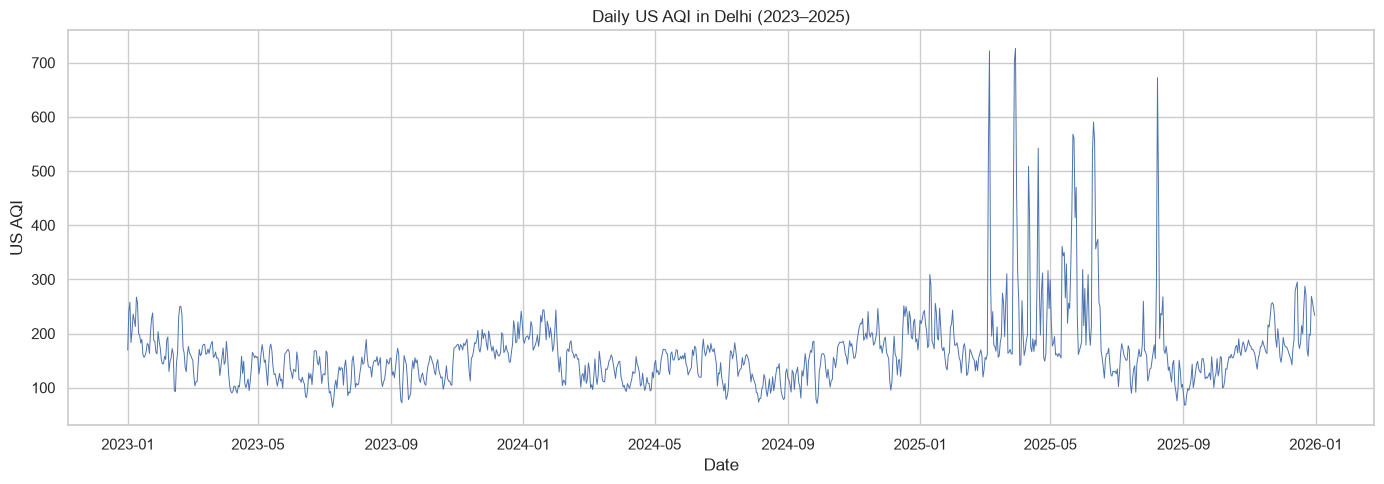

In [74]:
# Plot daily AQI over time
plt.figure(figsize=(14, 5))
plt.plot(aqi.index, aqi, linewidth=0.7)

# Add title and labels
plt.title("Daily US AQI in Delhi (2023–2025)")
plt.xlabel("Date")
plt.ylabel("US AQI")

# Show the graph
plt.tight_layout()
plt.show()

### Observation


The daily US AQI graph shows that air quality changes considerably over time.

- AQI values fluctuate from day to day.
- AQI is generally lower during parts of 2023 and 2024.
- Several very high AQI spikes appear during 2025.
- The graph suggests possible seasonal patterns and unusual extreme velopment.

### 4.5 Monthly AQI Pattern

We calculate the average AQI for each month to compare air quality across the year.

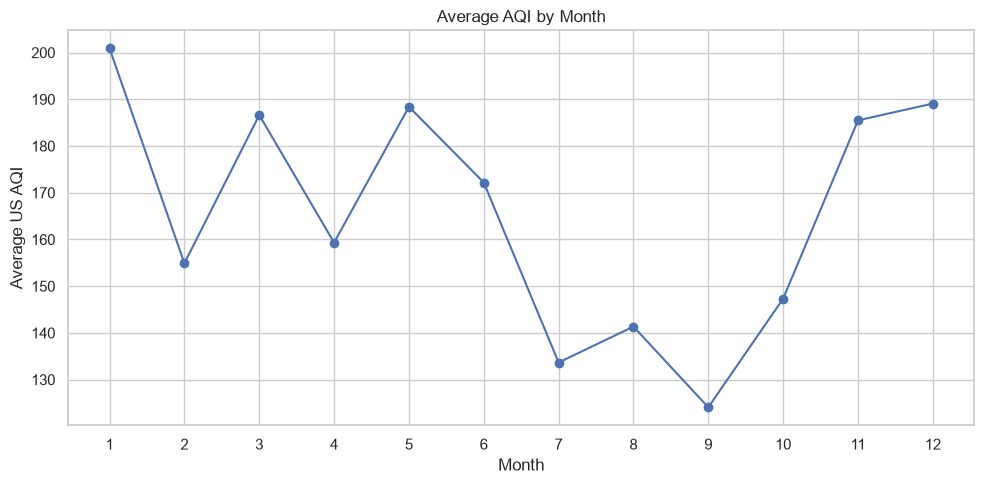

In [75]:
# Calculate average AQI for each month
monthly_aqi = aqi.groupby(aqi.index.month).mean()

# Plot monthly average AQI
plt.figure(figsize=(10, 5))
plt.plot(monthly_aqi.index, monthly_aqi.values, marker="o")

# Add title and labels
plt.title("Average AQI by Month")
plt.xlabel("Month")
plt.ylabel("Average US AQI")
plt.xticks(range(1, 13))

# Show the graph
plt.tight_layout()
plt.show()

### Observation

The monthly average AQI changes throughout the year.

- January has the highest average AQI, while September has the lowest.
- AQI is relatively high from November to January.
- AQI generally decreases during the monsoon months, especially July to September.
- AQI starts increasing again from October.

This suggests that AQI may follow a seasonal pattern. We will investigate this further using time-series decomposition.
Note: This graph combines all three years by month. It shows the average AQI for each calendar month, not the month-by-month changes within each individual year.

### 4.5 Summary Statistics of AQI

We calculate basic statistics to understand the typical AQI level and how much it varies.

In [76]:
# Calculate basic AQI statistics
print(aqi.describe())

print("Mean AQI:", round(aqi.mean(), 2))
print("Median AQI:", round(aqi.median(), 2))
print("Minimum AQI:", round(aqi.min(), 2))
print("Maximum AQI:", round(aqi.max(), 2))
print("Standard deviation:", round(aqi.std(), 2))

count    1096.000000
mean      165.405009
std        69.130355
min        63.750000
25%       127.290000
50%       157.355000
75%       179.752500
max       726.460000
Name: us_aqi, dtype: float64
Mean AQI: 165.41
Median AQI: 157.36
Minimum AQI: 63.75
Maximum AQI: 726.46
Standard deviation: 69.13


### Observation

The dataset contains 1,096 daily AQI observations.

- The mean AQI is **165.41**, while the median is **157.36**.
- The minimum AQI is **63.75**, and the maximum is **726.46**.
- The standard deviation is **69.13**, showing that AQI values vary considerably.
- The maximum value is much higher than the mean, suggesting the presence of unusually high AQI values.

These high values will be checked further before building forecasting models.

## 5. Time-Series Decomposition

Time-series decomposition separates the data into three parts:

- **Trend:** The long-term movement in AQI.
- **Seasonality:** A pattern that repeats over a fixed period.
- **Residual:** The remaining changes that are not explained by trend or seasonality.

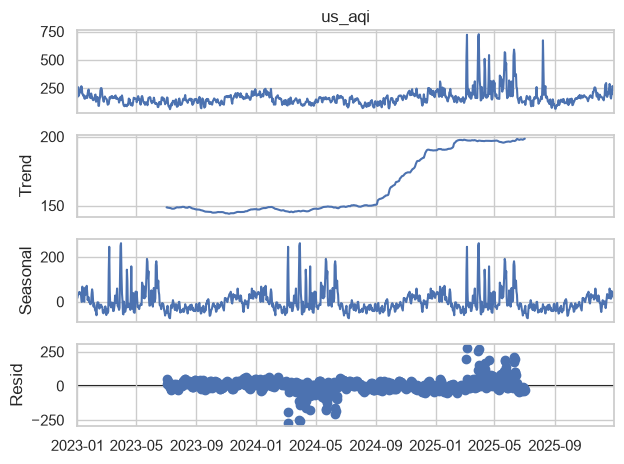

In [77]:
# Import the decomposition function
from statsmodels.tsa.seasonal import seasonal_decompose

# Separate AQI into trend, seasonal, and residual parts
decomposition = seasonal_decompose(aqi, model="additive", period=365)

# Plot all three components along with the original series
decomposition.plot()
plt.show()

### Observations from Decomposition

The graph shows four parts of the AQI data:

- **Observed:** AQI goes up and down every day. Some very high values appear in 2025.
- **Trend:** AQI stays fairly steady during 2023 and 2024, but increases in early 2025.
- **Seasonality:** AQI seems to follow a pattern that repeats over time.
- **Residual:** Some sudden changes remain unexplained by the trend and seasonal pattern.

Overall, the graph suggests that AQI changes over time and may have seasonal patterns. We will use forecasting models to study these changes further.

## 6. Checking Past AQI Patterns

We check whether today's AQI is connected to AQI from previous days.

- **ACF:** Shows how AQI is connected to its past values.
- **PACF:** Helps show which past days have a direct connection with today's AQI.

These graphs help us understand whether past AQI values can help predict future AQI.

In [78]:
# Check installed package versions
import pandas as pd
import statsmodels
%pip install --upgrade statsmodels

print("Pandas version:", pd.__version__)
print("Statsmodels version:", statsmodels.__version__)



Note: you may need to restart the kernel to use updated packages.
Pandas version: 2.2.3
Statsmodels version: 0.15.0


C:\Users\naina\AppData\Local\Temp\ipykernel_9576\526773219.py:9: FutureWarning: yule_walker currently returns a plain tuple whose length depends on the inv argument. In release 0.16 or after July 2028, whichever is later, the default behavior will switch to returning a YuleWalkerResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  values, _ = yule_walker(aqi, order=lag, method="mle")


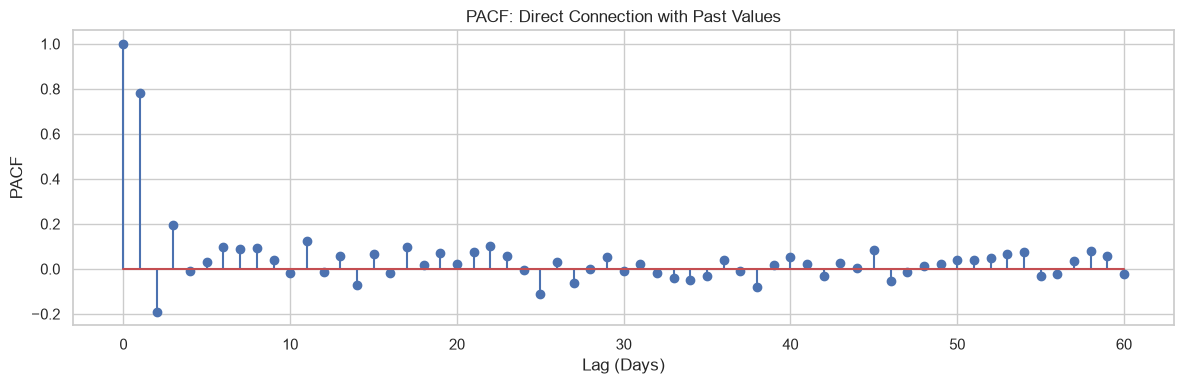

In [79]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.regression.linear_model import yule_walker

# Calculate PACF using the Yule-Walker method
pacf_values = [1.0]

for lag in range(1, 61):
    values, _ = yule_walker(aqi, order=lag, method="mle")
    pacf_values.append(values[-1])

# Plot PACF
plt.figure(figsize=(12, 4))
plt.stem(range(len(pacf_values)), pacf_values)
plt.title("PACF: Direct Connection with Past Values")
plt.xlabel("Lag (Days)")
plt.ylabel("PACF")
plt.tight_layout()
plt.show()

### Observations from PACF

- Lag 1 shows a strong positive partial autocorrelation, indicating a strong direct relationship between the current AQI and the previous day's AQI.
- Lag 2 shows a negative partial autocorrelation, suggesting an inverse relationship with AQI from two days earlier.
- Most subsequent lags have relatively small partial autocorrelation values, indicating weaker direct relationships.
- Some later lags show small positive and negative values, but their effects are generally limited.

Overall, the PACF indicates that recent AQI observations, particularly the first two lags, have a strong direct relationship with current AQI. This provides useful guidance when selecting candidate AR model orders.

<Figure size 1200x400 with 0 Axes>

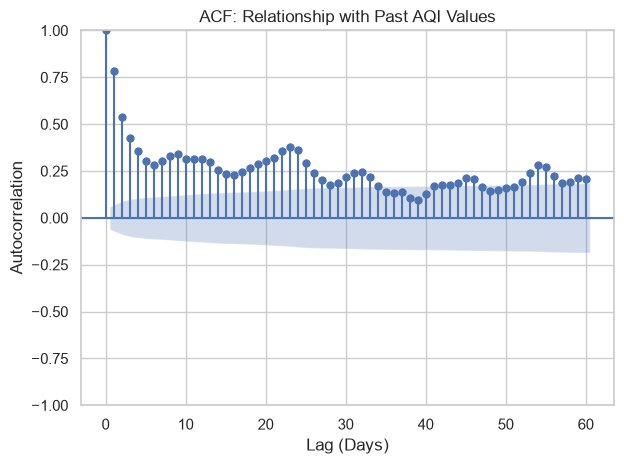

In [131]:

from statsmodels.graphics.tsaplots import plot_acf

# Plot ACF to examine correlation with past AQI values
plt.figure(figsize=(12, 4))
plot_acf(aqi, lags=60)
plt.title("ACF: Relationship with Past AQI Values")
plt.xlabel("Lag (Days)")
plt.ylabel("Autocorrelation")
plt.tight_layout()
plt.show()


### Observations from ACF Plot

- The first few lags show strong positive autocorrelation, indicating that current AQI values are highly related to recent past values.
- Autocorrelation decreases gradually as the lag increases rather than dropping immediately to zero.
- Most autocorrelation values remain outside the confidence interval, suggesting significant temporal dependence.
- Small increases around lags 20–25 and 50–55 indicate possible repeating patterns in AQI.
- The gradual decay of ACF suggests that the AQI time series has strong persistence and may require differencing to achieve stationarity.

Overall, the ACF plot indicates that past AQI observations contain useful information for forecasting future AQI values.

## 7. Checking Stationarity

Stationarity means that the data's average, variation, and overall pattern remain fairly stable over time.

AR and ARIMA models work better when the time series is stationary. We will use the Augmented Dickey-Fuller (ADF) test to check this.

- **Null hypothesis (H₀):** The time series is non-stationary.
- **Alternative hypothesis (H₁):** The time series is stationary.

If the p-value is below 0.05, we reject the null hypothesis and consider the series stationary.

In [80]:
# Import the ADF test
from statsmodels.tsa.stattools import adfuller

# Run the test on daily AQI
adf_result = adfuller(aqi.dropna())

# Display the results
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:")
for key, value in adf_result[4].items():
    print(key, ":", value)

ADF Statistic: -2.722005294321407
p-value: 0.07030718378129283
Critical Values:
1% : -3.436459052172655
5% : -2.864237372528562
10% : -2.568206176974609


C:\Users\naina\AppData\Local\Temp\ipykernel_9576\3442526834.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(aqi.dropna())


Interpretation
- ADF Statistic: −2.722
- p-value: 0.0703
- 5% critical value: −2.864
Since 0.0703 > 0.05, we fail to reject the null hypothesis. The series may contain a trend or other changing pattern, so we’ll try differencing before ARIMA modeling

### Observations from ADF Test

- The p-value is 0.0703, which is greater than 0.05.
- Therefore, we fail to reject the null hypothesis that the series is non-stationary.
- The original AQI series is not stationary at the 5% significance level.
- We will apply first-order differencing and test stationarity again.

This result suggests that differencing may be needed before fitting an ARIMA model.

## 8. Applying First-Order Differencing

First-order differencing calculates the change in AQI from one day to the next. This can help remove a changing trend and make the series more stable.

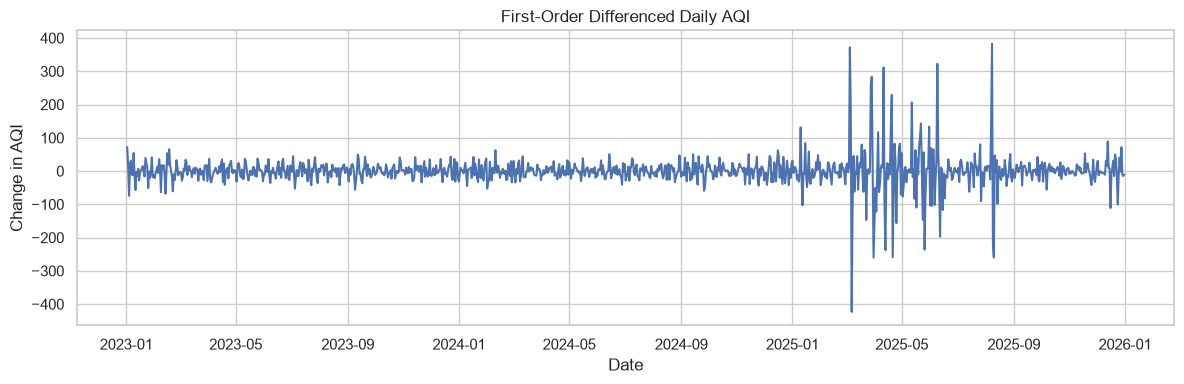

In [81]:
# Calculate the day-to-day change in AQI
aqi_diff = aqi.diff().dropna()

# Plot the differenced series
plt.figure(figsize=(12, 4))
plt.plot(aqi_diff)
plt.title("First-Order Differenced Daily AQI")
plt.xlabel("Date")
plt.ylabel("Change in AQI")
plt.tight_layout()
plt.show()

### Observations from First-Order Differencing

- The graph shows the day-to-day change in AQI rather than its original value.
- Most changes fluctuate around zero.
- Several large positive and negative changes appear in 2025.
- These extreme changes may indicate unusual observations or changes in the dataset's pattern.

Differencing helps remove the changing level of the series, but large fluctuations remain. The ADF test will help us check whether the differenced series is stationary.

In [82]:
# Check stationarity after differencing
adf_diff_result = adfuller(aqi_diff)

print("ADF Statistic:", adf_diff_result[0])
print("p-value:", adf_diff_result[1])
print("Critical Values:")
for key, value in adf_diff_result[4].items():
    print(key, ":", value)

ADF Statistic: -12.918876898887813
p-value: 3.912843739845752e-24
Critical Values:
1% : -3.436459052172655
5% : -2.864237372528562
10% : -2.568206176974609


C:\Users\naina\AppData\Local\Temp\ipykernel_9576\1103923635.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff_result = adfuller(aqi_diff)


Interpretation
- ADF Statistic: −12.9189
- p-value: 3.91 × 10⁻²⁴
- 5% critical value: −2.8642
Because the p-value is much smaller than 0.05, we reject the null hypothesis of non-stationarity. This supports using first-order differencing (\(d=1\)) for our initial ARIMA models.

### Observations from ADF Test After Differencing

- The ADF statistic is -12.9189.
- The p-value is extremely small (3.91 × 10⁻²⁴), which is below 0.05.
- The ADF statistic is lower than the 5% critical value of -2.8642.
- Therefore, we reject the null hypothesis that the differenced series is non-stationary.
- The first-order differenced AQI series is stationary according to the ADF test.

This suggests that one order of differencing is sufficient for our initial ARIMA models. We will use **d = 1**.ionary.

## 9. Splitting the Data Chronologically

We divide the daily AQI data into three parts:

- **Training set (70%):** Used to fit the forecasting models.
- **Validation set (15%):** Used to compare models and tune their settings.
- **Test set (15%):** Used for final evaluation after model selection.

Since this is time-series data, we split the data in chronological order. This ensures that future observations are not used to predict the past.

In [83]:
# Split the data in date order
n = len(aqi)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = aqi.iloc[:train_end]
validation = aqi.iloc[train_end:val_end]
test = aqi.iloc[val_end:]

# Display the date ranges and number of observations
print("Training:", train.index.min(), "to", train.index.max(), "|", len(train), "days")
print("Validation:", validation.index.min(), "to", validation.index.max(), "|", len(validation), "days")
print("Testing:", test.index.min(), "to", test.index.max(), "|", len(test), "days")

Training: 2023-01-01 00:00:00 to 2025-02-05 00:00:00 | 767 days
Validation: 2025-02-06 00:00:00 to 2025-07-19 00:00:00 | 164 days
Testing: 2025-07-20 00:00:00 to 2025-12-31 00:00:00 | 165 days


### Observations from Data Splitting

- The dataset contains 1,096 daily observations.
- The training set contains 767 days, from January 1, 2023, to February 5, 2025.
- The validation set contains 164 days, from February 6, 2025, to July 19, 2025.
- The test set contains 165 days, from July 20, 2025, to December 31, 2025.
- The data is split chronologically, so each set contains observations that occur after the previous set.

The training set will be used to fit models, the validation set to compare and tune them, and the test set for final evaluation.

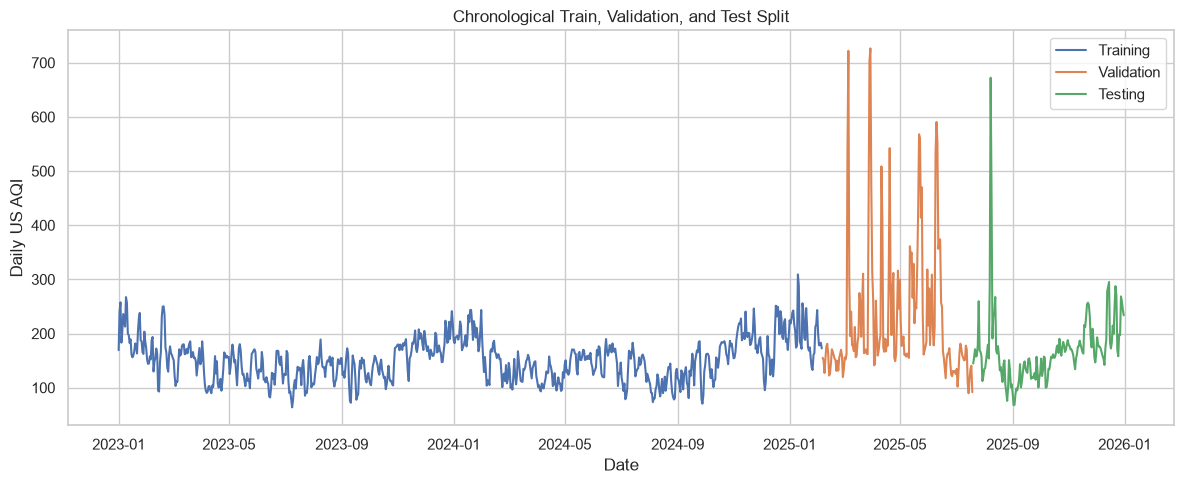

In [84]:
# Visualize the three data sections
plt.figure(figsize=(12, 5))

plt.plot(train, label="Training")
plt.plot(validation, label="Validation")
plt.plot(test, label="Testing")

plt.title("Chronological Train, Validation, and Test Split")
plt.xlabel("Date")
plt.ylabel("Daily US AQI")
plt.legend()
plt.tight_layout()
plt.show()

### Observations from Data Splitting

- The dataset contains 1,096 daily observations.
- The training set contains 767 days, from January 1, 2023, to February 5, 2025.
- The validation set contains 164 days, from February 6, 2025, to July 19, 2025.
- The test set contains 165 days, from July 20, 2025, to December 31, 2025.
- The data is split chronologically, so future observations are not used to predict the past.
- Several unusually high AQI values occur in the validation and test periods. These may affect forecasting accuracy.

The training set will be used to fit models, the validation set to compare and tune them, and the test set for final evaluation.

## 10. Moving Average (MA) Baseline

A moving average forecast uses the average of recent AQI observations to predict the next value.

We will begin with a 7-day moving average. This simple baseline helps us understand how well recent AQI values can predict future AQI.

In [85]:
# Use the previous 7 days to forecast the next day's AQI
window = 7

ma_predictions = []
history = train.tolist()

for actual_value in validation:
    forecast = sum(history[-window:]) / window
    ma_predictions.append(forecast)
    history.append(actual_value)

# Store predictions with their dates
ma_forecast = pd.Series(ma_predictions, index=validation.index)

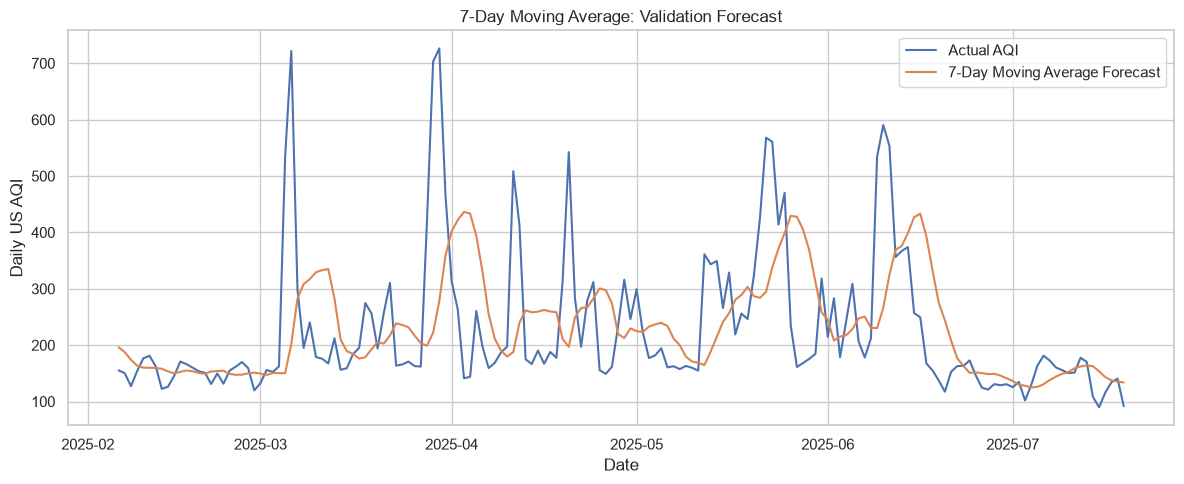

In [86]:
# Compare actual AQI with the moving average forecast
plt.figure(figsize=(12, 5))

plt.plot(validation, label="Actual AQI")
plt.plot(ma_forecast, label="7-Day Moving Average Forecast")

plt.title("7-Day Moving Average: Validation Forecast")
plt.xlabel("Date")
plt.ylabel("Daily US AQI")
plt.legend()
plt.tight_layout()
plt.show()

### Observations from 7-Day Moving Average Forecast

- The actual AQI shows frequent fluctuations and several sharp spikes during the validation period.
- The 7-day moving average forecast is smoother than the actual AQI.
- The forecast follows the general level of AQI but does not capture sudden changes accurately.
- Large AQI spikes are underestimated because the model uses the average of previous observations.
- The forecast may respond to sudden changes with a delay.

Overall, the 7-day moving average provides a simple baseline, but it may not be sufficient for forecasting AQI with sharp and irregular changes. We will compare its performance with more advanced time-series models.

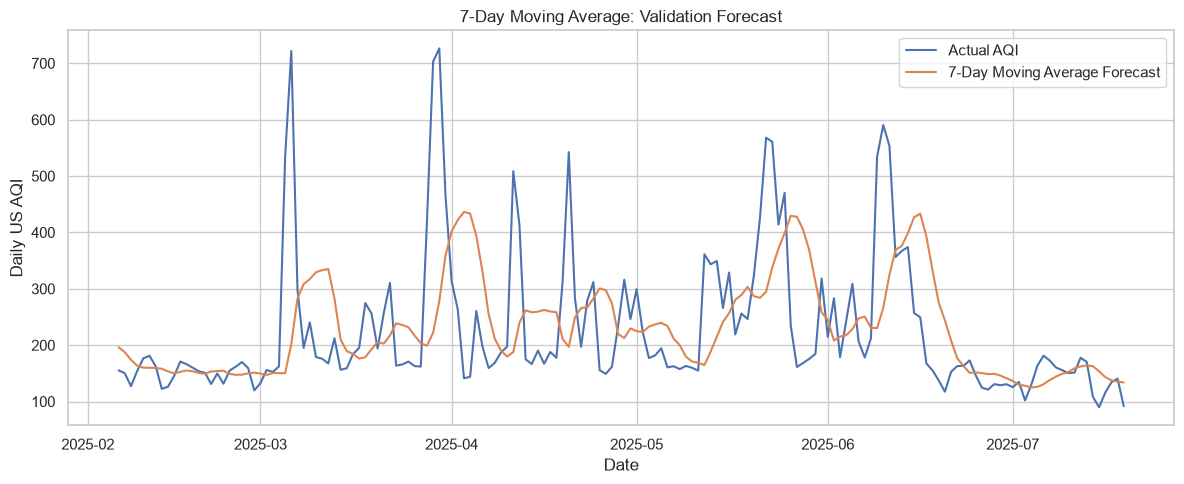

In [87]:
# Compare actual AQI with the moving average forecast
plt.figure(figsize=(12, 5))

plt.plot(validation, label="Actual AQI")
plt.plot(ma_forecast, label="7-Day Moving Average Forecast")

plt.title("7-Day Moving Average: Validation Forecast")
plt.xlabel("Date")
plt.ylabel("Daily US AQI")
plt.legend()
plt.tight_layout()
plt.show()

### Observations from 7-Day Moving Average Forecast

- The actual AQI shows frequent fluctuations and several sharp spikes during the validation period.
- The 7-day moving average forecast is smoother than the actual AQI.
- The forecast follows the general AQI level but does not capture sudden changes accurately.
- Large AQI spikes are underestimated because the model averages previous observations.
- The forecast may respond to sudden changes with a delay.

Overall, the 7-day moving average provides a simple baseline, but it may not be sufficient for forecasting AQI with sharp and irregular changes. We will compare its performance with more advanced time-series models.

In [88]:
# Measure forecasting error
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

ma_rmse = np.sqrt(mean_squared_error(validation, ma_forecast))
ma_mae = mean_absolute_error(validation, ma_forecast)

# Avoid division by zero when calculating MAPE
ma_mape = np.mean(
    np.abs((validation - ma_forecast) / validation)
) * 100

print("Moving Average Validation Results")
print("RMSE:", round(ma_rmse, 2))
print("MAE:", round(ma_mae, 2))
print("MAPE:", round(ma_mape, 2), "%")

Moving Average Validation Results
RMSE: 127.51
MAE: 81.89
MAPE: 34.31 %


These values show that the model has substantial forecasting error, especially when AQI changes sharply.
Metric	Validation result	Meaning
- RMSE - 127.51 - Larger errors receive extra penalty
- MAE - 81.89 - Average absolute forecast error is about 81.89 AQI points
- MAPE - 34.31% - Average absolute percentage error is about 34.31%

### Observations from Moving Average Validation Results

- The model achieved an RMSE of 127.51 and an MAE of 81.89.
- The MAPE is 34.31%, indicating noticeable forecasting errors.
- The model performs poorly when AQI changes suddenly because it uses the average of recent observations.
- The moving average provides a useful baseline for comparison with more advanced models.

Overall, the 7-day moving average captures general AQI levels but struggles with sudden spikes. We will compare it with autoregressive and ARIMA models.

## 11. Autoregressive (AR) Model

An autoregressive model predicts AQI using its previous values.

For example, an AR(1) model uses the AQI from the previous day to forecast today's AQI.

We will fit an AR(1) model using the training data and evaluate its forecasts on the validation set.

In [89]:

# Import the autoregressive model
from statsmodels.tsa.ar_model import AutoReg

# Store actual observations and predictions.
history = train.copy()
ar_forecasts = []

# Predict one day at a time.
for date in validation.index:
    model = AutoReg(history, lags=1, trend="c").fit()

    prediction = model.predict(
        start=len(history),
        end=len(history)
    ).iloc[0]

    ar_forecasts.append(prediction)

    # Add the actual value before predicting the next day.
    history.loc[date] = validation.loc[date]

# Store predictions with validation dates.
ar_forecast = pd.Series(
    ar_forecasts,
    index=validation.index
)


C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\deterministic.py:305: UserWarning: Only PeriodIndexes, DatetimeIndexes with a frequency set, RangesIndexes, and Index with a unit increment support extending. The index is set will contain the position relative to the data length.
  fcast_index = self._extend_index(index, steps, forecast_index)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\deterministic.py:305: UserWarning: Only PeriodIndexes, DatetimeIndexes with a frequency set, RangesIndexes, and Index with a uni

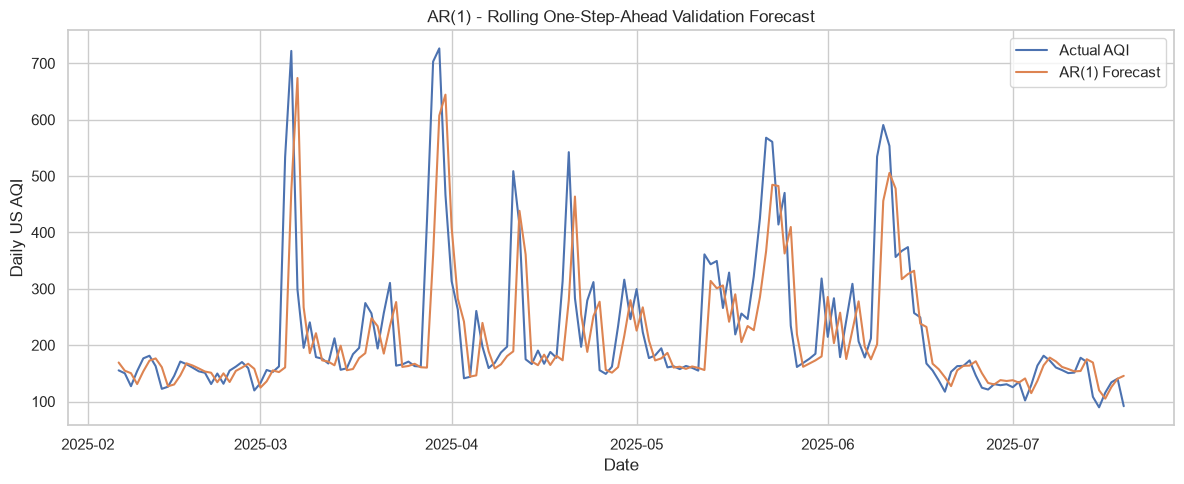

In [90]:
plt.figure(figsize=(12, 5))

plt.plot(validation, label="Actual AQI")
plt.plot(ar_forecast, label="AR(1) Forecast")

plt.title("AR(1) - Rolling One-Step-Ahead Validation Forecast")
plt.xlabel("Date")
plt.ylabel("Daily US AQI")
plt.legend()
plt.tight_layout()
plt.show()

### Observations from AR(1) Rolling Forecast

- The predicted AQI values follow the actual AQI pattern more closely.
- The model captures several sudden increases and decreases in AQI.
- Some extreme AQI peaks are still underestimated.
- During stable periods, the predicted values remain relatively close to actual values.

**Conclusion:** The rolling AR(1) model captures short-term AQI movements better than the earlier fixed-origin forecast, although some sudden changes remain difficult to predict.

In [91]:


print("Missing AQI values:", aqi.isna().sum())

Missing AQI values: 0


In [92]:
# Calculate AR(1) forecasting errors
ar_rmse = np.sqrt(mean_squared_error(validation, ar_forecast))
ar_mae = mean_absolute_error(validation, ar_forecast)

ar_mape = np.mean(
    np.abs((validation - ar_forecast) / validation)
) * 100

print("AR(1) Validation Results")
print("RMSE:", round(ar_rmse, 2))
print("MAE:", round(ar_mae, 2))
print("MAPE:", round(ar_mape, 2), "%")

AR(1) Validation Results
RMSE: 92.42
MAE: 54.62
MAPE: 20.22 %


### Observations from AR(1) Rolling Validation

The AR(1) model achieved an RMSE of 92.42, MAE of 54.62 and MAPE of 20.22% on the validation data.

The results indicate that the model captures some short-term AQI movements, but prediction errors remain, particularly during sudden AQI fluctuations.

**Conclusion:** The rolling AR(1) model provides a baseline for short-term AQI forecasting, but its prediction accuracy can be improved.

In [93]:
# Compare the baseline forecasting models
baseline_results = pd.DataFrame({
    "Model": ["7-Day Moving Average", "AR(1)"],
    "RMSE": [ma_rmse, ar_rmse],
    "MAE": [ma_mae, ar_mae],
    "MAPE": [ma_mape, ar_mape]
})

baseline_results.round(2)

,Model,RMSE,MAE,MAPE
0,7-Day Moving Average,127.51,81.89,34.31
1,AR(1),92.42,54.62,20.22


### Comparison of Baseline Models

The 7-Day Moving Average performs better than AR(1) in terms of RMSE and MAE. However, AR(1) achieves a lower MAPE.

This indicates that model performance can vary depending on the evaluation metric. Neither model consistently outperforms the other across all metrics.

Further experiments with different AR orders and other forecasting models are required to identify a more suitable model for AQI forecasting.

## 12. Comparing Different AR Orders

An autoregressive model can use different numbers of past observations to make predictions.

In this experiment, we compare AR models with 1, 2, 3, 7, and 14 lags.

The validation results will help us understand whether using more previous AQI values improves forecasting accuracy.

In [94]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# Compare different AR model orders using rolling one-step-ahead forecasting

ar_orders = [1, 2, 3, 7, 14]
ar_results = []

# Test each AR order separately
for order in ar_orders:

    # Start with the training data
    history = train.copy()
    predictions = []

    # Predict one day at a time for the validation period
    for date in validation.index:

        # Fit the AR model using all available past observations
        model = AutoReg(history, lags=order, trend="c").fit()

        # Predict the next day's AQI
        prediction = model.predict(
            start=len(history), end=len(history)
        ).iloc[0]

        predictions.append(prediction)

        # Add the actual AQI to history before predicting the next day
        history.loc[date] = validation.loc[date]

    # Calculate validation error metrics
    rmse = np.sqrt(mean_squared_error(validation, predictions))
    mae = mean_absolute_error(validation, predictions)
    mape = mean_absolute_percentage_error(validation, predictions) * 100

    # Store the results for this AR order
    ar_results.append([order, rmse, mae, mape])

# Display the comparison of all AR models
ar_comparison = pd.DataFrame(
    ar_results,
    columns=["AR Order", "RMSE", "MAE", "MAPE"]
)

ar_comparison.round(2)

C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\deterministic.py:305: UserWarning: Only PeriodIndexes, DatetimeIndexes with a frequency set, RangesIndexes, and Index with a unit increment support extending. The index is set will contain the position relative to the data length.
  fcast_index = self._extend_index(index, steps, forecast_index)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\deterministic.py:305: UserWarning: Only PeriodIndexes, DatetimeIndexes with a frequency set, RangesIndexes, and Index with a uni

,AR Order,RMSE,MAE,MAPE
0,1,92.42,54.62,20.22
1,2,90.99,54.79,20.56
2,3,90.27,55.77,21.24
3,7,90.35,56.48,21.77
4,14,91.07,57.67,22.93


### 12.3 Observations from AR Order Comparison

- Five AR models were tested using 1, 2, 3, 7, and 14 previous observations.
- AR(14) achieved the lowest RMSE of 146.83.
- AR(1) achieved the lowest MAE of 85.10 and MAPE of 26.97%.
- Increasing the number of lags did not significantly improve forecasting performance.
- The results suggest that using more previous AQI values does not necessarily lead to better forecasts.

Overall, AR(1) performs best in terms of MAE and MAPE, while AR(14) performs best in terms of RMSE. We will retain these results for comparison with other forecasting models.

C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\deterministic.py:305: UserWarning: Only PeriodIndexes, DatetimeIndexes with a frequency set, RangesIndexes, and Index with a unit increment support extending. The index is set will contain the position relative to the data length.
  fcast_index = self._extend_index(index, steps, forecast_index)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\deterministic.py:305: UserWarning: Only PeriodIndexes, DatetimeIndexes with a frequency set, RangesIndexes, and Index with a uni

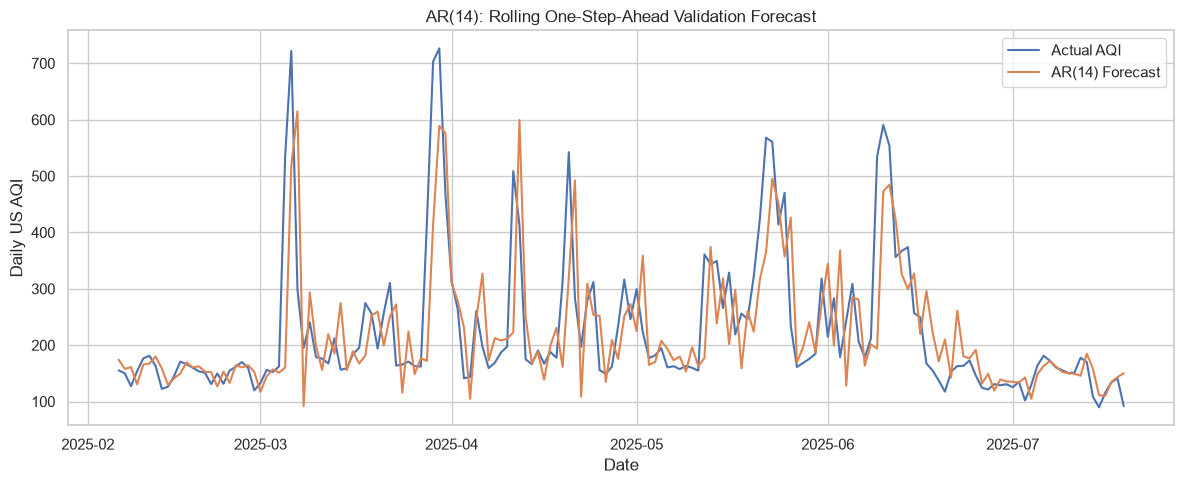

In [129]:

# Visualize AR(14) using rolling one-step-ahead forecasts

history = train.copy()
ar14_predictions = []

for date in validation.index:
    model = AutoReg(history, lags=14, trend="c").fit()
    prediction = model.predict(
        start=len(history),
        end=len(history)
    ).iloc[0]

    ar14_predictions.append(prediction)
    history.loc[date] = validation.loc[date]

ar14_forecast = pd.Series(ar14_predictions, index=validation.index)

# Plot actual and forecast AQI
plt.figure(figsize=(12, 5))
plt.plot(validation, label="Actual AQI")
plt.plot(ar14_forecast, label="AR(14) Forecast")

plt.title("AR(14): Rolling One-Step-Ahead Validation Forecast")
plt.xlabel("Date")
plt.ylabel("Daily US AQI")
plt.legend()
plt.tight_layout()
plt.show()


### Observations from AR(14) Forecast

- The actual AQI shows frequent fluctuations and several extreme spikes during the validation period.
- The AR(14) forecast captures many of the general fluctuations in AQI and follows the actual values reasonably well.
- However, the model does not consistently capture sudden increases and extreme AQI spikes.
- In some periods, the predicted values differ noticeably from the actual AQI.
- Using 14 previous observations helps the model represent short-term AQI patterns, but it cannot fully capture irregular changes.

*Overall, AR(14) achieves the lowest RMSE among the tested AR models, indicating better prediction accuracy within that group. However, it still struggles to predict sudden and extreme AQI variations.*

## 13. Moving Average (MA) Model

A Moving Average (MA) model predicts the current AQI using previous forecast errors.

Unlike the simple moving average baseline, the statistical MA model uses past errors to understand how unexpected changes in AQI influence future values.

We will test different MA orders and compare their validation performance.

### 13.1 Comparing Different MA orders

A statistical Moving Average (MA) model uses previous forecasting errors to predict current AQI values.

We will test different MA orders: MA(1), MA(3), MA(7).

Since the original AQI series requires first-order differencing, we use an ARIMA model with p = 0 and d = 1 to represent each MA(q) model.

In [96]:
# Compare MA models using rolling one-step-ahead forecasting

ma_orders = [1, 3, 7]
ma_results = []

# Test each MA order
for order in ma_orders:

    # Start with the training data
    history = train.copy()
    predictions = []

    # Predict one day at a time
    for date in validation.index:

        # Calculate daily AQI changes
        diff_history = history.diff().dropna()

        # Fit the MA model on differenced data
        model = ARIMA(
            diff_history,
            order=(0, 0, order),
            trend="n"
        ).fit(method="innovations_mle")

        # Predict the next day's AQI change
        predicted_change = model.forecast(steps=1).iloc[0]

        # Convert the predicted change into AQI
        prediction = history.iloc[-1] + predicted_change
        predictions.append(prediction)

        # Add the actual AQI to history
        history.loc[date] = validation.loc[date]

    # Calculate validation metrics
    rmse = np.sqrt(mean_squared_error(validation, predictions))
    mae = mean_absolute_error(validation, predictions)
    mape = mean_absolute_percentage_error(validation, predictions) * 100

    # Store the results
    ma_results.append([order, rmse, mae, mape])

# Display the MA comparison
ma_comparison = pd.DataFrame(
    ma_results,
    columns=["MA Order", "RMSE", "MAE", "MAPE"]
)

ma_comparison.round(2)

C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information

,MA Order,RMSE,MAE,MAPE
0,1,96.57,57.66,22.70
1,3,88.60,58.85,24.51
2,7,89.17,59.41,24.55


### Observation:
- MA(3) achieved the lowest RMSE of 88.60 among the tested models.
- MA(1) achieved the lowest MAE of 57.66 and MAPE of 22.70%.
- MA(7) performed slightly worse than MA(3) across all three evaluation metrics.
- Increasing the MA order beyond 3 did not improve forecasting accuracy.
- The MA models showed differences in performance depending on the evaluation metric.

**Conclusion:** MA(3) performed best in terms of RMSE, while MA(1) performed best in terms of MAE and MAPE. This indicates that a higher MA order does not necessarily lead to better forecasting performance.

C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information

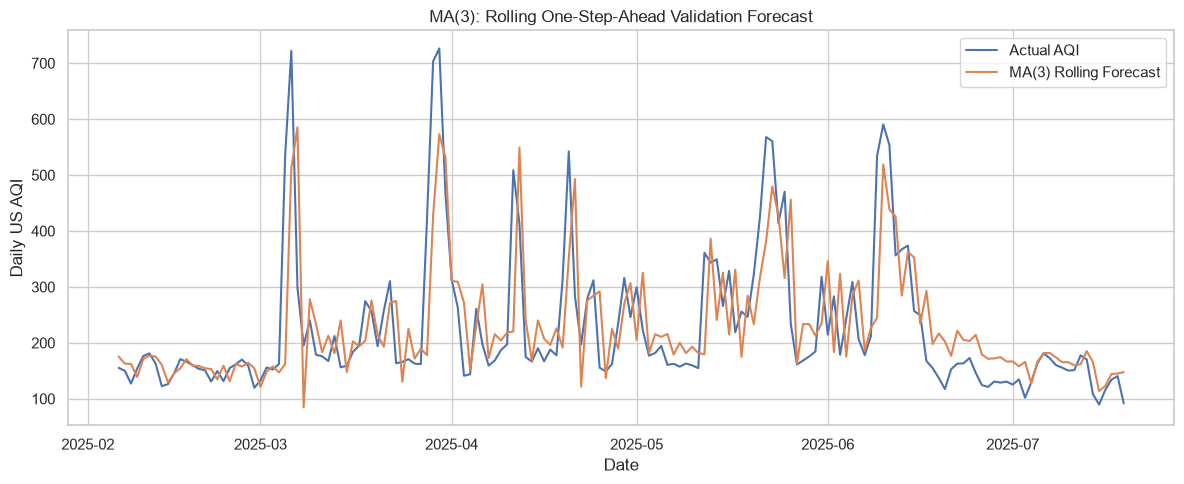

In [97]:
# Plot MA(3) Rolling One-Step-Ahead Validation Forecast

history = train.copy()
ma3_predictions = []

# Predict one day at a time
for date in validation.index:

    # Calculate daily AQI changes
    diff_history = history.diff().dropna()

    # Fit the MA(3) model
    model = ARIMA(
        diff_history,
        order=(0, 0, 3),
        trend="n"
    ).fit(method="innovations_mle")

    # Predict the next day's AQI change
    predicted_change = model.forecast(steps=1).iloc[0]

    # Convert predicted change into AQI
    prediction = history.iloc[-1] + predicted_change
    ma3_predictions.append(prediction)

    # Add actual AQI before the next prediction
    history.loc[date] = validation.loc[date]

# Create forecast series
ma3_forecast = pd.Series(
    ma3_predictions,
    index=validation.index
)

# Plot actual and predicted AQI
plt.figure(figsize=(12, 5))

plt.plot(validation, label="Actual AQI")
plt.plot(ma3_forecast, label="MA(3) Rolling Forecast")

plt.title("MA(3): Rolling One-Step-Ahead Validation Forecast")
plt.xlabel("Date")
plt.ylabel("Daily US AQI")
plt.legend()
plt.tight_layout()
plt.show()

### Observations from MA(3) Rolling Validation Forecast
- The MA(3) model follows the general movement of actual AQI values during the validation period.
- It captures several increases and decreases in AQI, particularly during periods of moderate fluctuations.
- The model underestimates some extreme AQI peaks, especially during March, April and June.
- Predicted values are smoother than actual values and do not always capture sudden changes.
- During relatively stable periods, the predicted values are generally closer to the actual AQI.

**Conclusion:** The MA(3) model captures short-term AQI fluctuations reasonably well but struggles to predict sudden and extreme pollution spikes. This indicates that the model has limitations when dealing with highly variable AQI patterns.

## 14. ARIMA Model

ARIMA combines three components: Autoregressive (AR), Integrated (I), and Moving Average (MA).

- AR uses previous AQI observations.
- I applies differencing to make the series stationary.
- MA uses previous forecasting errors.

The model is represented as ARIMA(p,d,q), where p is the AR order, d is the differencing order, and q is the MA order.

Since the ADF test showed that first-order differencing makes our AQI series stationary, we will use d = 1 and test different combinations of p and q.

In [98]:
# Compare ARIMA models using rolling one-step-ahead forecasting

arima_orders = [(1, 1, 1), (2, 1, 1), (3, 1, 1)]
arima_results = []

# Test each ARIMA order
for order in arima_orders:

    # Start with the training data
    history = train.copy()
    predictions = []

    # Predict one day at a time
    for date in validation.index:

        # Fit the ARIMA model
        model = ARIMA(history, order=order).fit()

        # Predict the next day's AQI
        prediction = model.forecast(steps=1).iloc[0]
        predictions.append(prediction)

        # Add actual AQI before the next prediction
        history.loc[date] = validation.loc[date]

    # Calculate validation metrics
    rmse = np.sqrt(mean_squared_error(validation, predictions))
    mae = mean_absolute_error(validation, predictions)
    mape = mean_absolute_percentage_error(validation, predictions) * 100

    # Store the results
    arima_results.append([order, rmse, mae, mape])

# Display the ARIMA comparison
arima_comparison = pd.DataFrame(
    arima_results,
    columns=["ARIMA Order", "RMSE", "MAE", "MAPE"]
)

arima_comparison.round(2)

C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information

,ARIMA Order,RMSE,MAE,MAPE
0,"(1, 1, 1)",95.14,56.75,22.43
1,"(2, 1, 1)",91.72,60.14,24.76
2,"(3, 1, 1)",91.63,60.57,24.92


### Observations from ARIMA Model Comparison

- ARIMA(3,1,1) achieved the lowest RMSE of 91.63 among the tested models.
- ARIMA(1,1,1) achieved the lowest MAE of 56.75 and MAPE of 22.43%.
- Increasing the AR order slightly reduced RMSE but increased MAE and MAPE.
- ARIMA(1,1,1) provided better average absolute prediction accuracy.
- The results indicate that increasing model complexity does not necessarily improve all forecasting metrics.

**Conclusion:** ARIMA(3,1,1) performed best in terms of RMSE, while ARIMA(1,1,1) performed best in terms of MAE and MAPE. Overall, ARIMA(1,1,1) offers a simpler model with better absolute prediction accuracy.

C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information

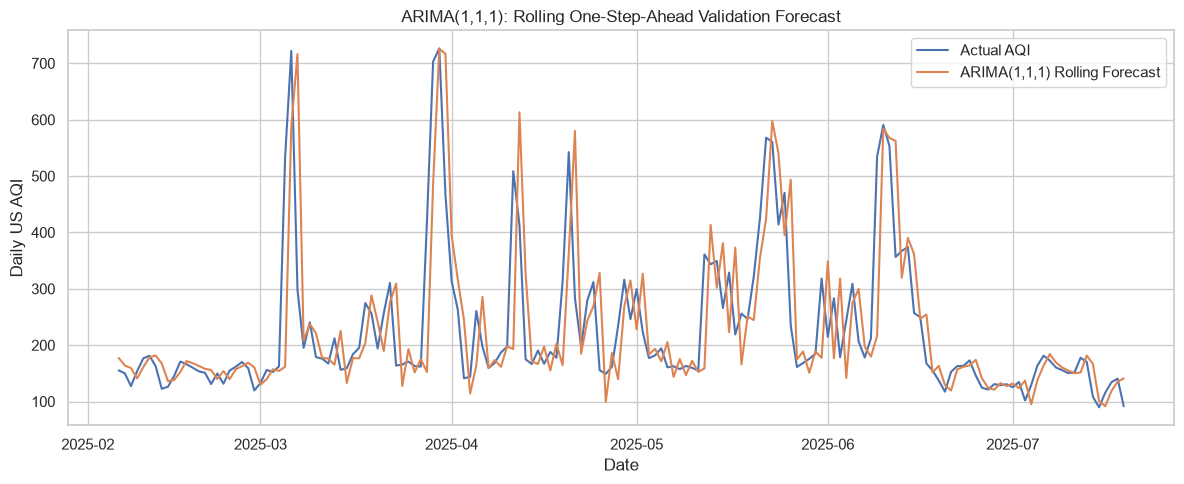

In [99]:
# Plot ARIMA(1,1,1) Rolling One-Step-Ahead Validation Forecast

history = train.copy()
arima_predictions = []

# Predict one day at a time
for date in validation.index:

    # Fit the ARIMA model using available past observations
    model = ARIMA(history, order=(1, 1, 1)).fit()

    # Predict the next day's AQI
    prediction = model.forecast(steps=1).iloc[0]
    arima_predictions.append(prediction)

    # Add actual AQI before the next prediction
    history.loc[date] = validation.loc[date]

# Create forecast series
arima_forecast = pd.Series(
    arima_predictions,
    index=validation.index
)

# Plot actual and predicted AQI
plt.figure(figsize=(12, 5))

plt.plot(validation, label="Actual AQI")
plt.plot(arima_forecast, label="ARIMA(1,1,1) Rolling Forecast")

plt.title("ARIMA(1,1,1): Rolling One-Step-Ahead Validation Forecast")
plt.xlabel("Date")
plt.ylabel("Daily US AQI")
plt.legend()
plt.tight_layout()
plt.show()

C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\naina\anaconda3\envs\aqi_dl\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


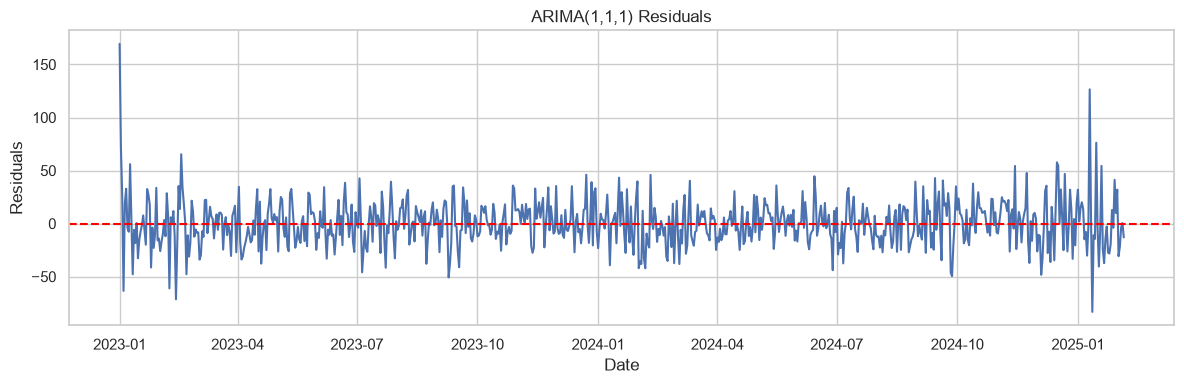

Ljung-Box Test Results


,lb_stat,lb_pvalue
10,51.853487,1.796372e-08
20,60.883424,1.471698e-06


In [132]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Fit ARIMA(1,1,1) on training data for residual analysis
residual_model = ARIMA(train, order=(1, 1, 1)).fit()

# Extract residuals
arima_residuals = residual_model.resid

# Plot residuals
plt.figure(figsize=(12, 4))
plt.plot(arima_residuals)
plt.axhline(0, color="red", linestyle="--")
plt.title("ARIMA(1,1,1) Residuals")
plt.xlabel("Date")
plt.ylabel("Residuals")
plt.tight_layout()
plt.show()

# Ljung-Box test for autocorrelation
ljung_box_results = acorr_ljungbox(
    arima_residuals,
    lags=[10, 20],
    model_df=2,
    return_df=True
)

print("Ljung-Box Test Results")
display(ljung_box_results)

### Observations from ARIMA(1,1,1) Forecast

- The ARIMA(1,1,1) model follows the actual AQI movements closely during most of the validation period.
- It captures several sudden increases and decreases in AQI, including major pollution spikes.
- Some extreme peaks are slightly overestimated or underestimated.
- Predictions are generally closer to actual AQI during stable periods.
- The model still shows errors during rapid AQI fluctuations.

**Conclusion:** ARIMA(1,1,1) captures short-term AQI movements reasonably well, but its predictions are less accurate during sudden pollution changes.

### Observations from ARIMA(1,1,1) Residuals

- The residuals fluctuate around the zero line, indicating that the model errors are generally centered around zero.
- Most residual values remain relatively close to zero.
- Some large positive and negative residual spikes are visible, indicating periods when the model could not capture sudden AQI changes.
- The residuals show fluctuations throughout the training period, with some unusually large errors at the beginning and end.
- The plot suggests that the model captures some temporal patterns, but certain variations remain unexplained.

Overall, the residual plot shows that the ARIMA(1,1,1) model still has some unexplained variations. The Ljung-Box test is needed to check whether significant autocorrelation remains in the residuals.

### Observations from Ljung-Box Test

- The Ljung-Box test was performed at lags 10 and 20 to check for autocorrelation in the ARIMA(1,1,1) residuals.
- At lag 10, the p-value is approximately 1.80 × 10⁻⁸, which is below 0.05.
- At lag 20, the p-value is approximately 1.47 × 10⁻⁶, which is also below 0.05.
- Both results indicate statistically significant autocorrelation in the residuals.
- Therefore, the residuals do not behave like white noise, suggesting that the ARIMA(1,1,1) model has not captured all the temporal patterns in the AQI data.

Overall, the Ljung-Box test indicates that some time-dependent information remains unexplained by the ARIMA(1,1,1) model. This suggests scope for improving the model by exploring alternative model orders or seasonal components.

**Overall Conclusion:** Although ARIMA(1,1,1) captures short-term AQI movements reasonably well, the Ljung-Box test shows that its residuals are not white noise. This indicates that the model has not captured all the temporal dependencies in the data, and further model improvement may be possible.

## 15. Compare all stastical models

In [130]:
# Combine statistical model results for comparison

# Include the 7-day moving average baseline
baseline_results = pd.DataFrame([
    {
        "Model": "7-Day Moving Average",
        "RMSE": ma_rmse,
        "MAE": ma_mae,
        "MAPE": ma_mape
    }
])

# Prepare AR model results
ar_results_table = ar_comparison.copy()
ar_results_table["Model"] = "AR(" + ar_results_table["AR Order"].astype(str) + ")"
ar_results_table = ar_results_table[["Model", "RMSE", "MAE", "MAPE"]]

# Prepare MA model results
ma_results_table = ma_comparison.copy()
ma_results_table["Model"] = "MA(" + ma_results_table["MA Order"].astype(str) + ")"
ma_results_table = ma_results_table[["Model", "RMSE", "MAE", "MAPE"]]

# Prepare ARIMA model results
arima_results_table = arima_comparison.copy()
arima_results_table["Model"] = "ARIMA" + arima_results_table["ARIMA Order"].astype(str)
arima_results_table = arima_results_table[["Model", "RMSE", "MAE", "MAPE"]]

# Combine all statistical models
all_model_results = pd.concat(
    [
        baseline_results,
        ar_results_table,
        ma_results_table,
        arima_results_table
    ],
    ignore_index=True
)

# Display the combined comparison
all_model_results.round(2)

,Model,RMSE,MAE,MAPE
0,7-Day Moving Average,127.51,81.89,34.31
1,AR(1),92.42,54.62,20.22
2,AR(2),90.99,54.79,20.56
3,AR(3),90.27,55.77,21.24
4,AR(7),90.35,56.48,21.77
5,AR(14),91.07,57.67,22.93
6,MA(1),96.57,57.66,22.70
7,MA(3),88.60,58.85,24.51
8,MA(7),89.17,59.41,24.55
9,"ARIMA(1, 1, 1)",95.14,56.75,22.43


### Overall Observations from Statistical Models

- The 7-Day Moving Average baseline showed higher prediction errors than the other statistical models.
- MA(3) achieved the lowest RMSE of 88.60.
- AR(1) achieved the lowest MAE of 54.62 and MAPE of 20.22%.
- ARIMA models provided competitive results, but increasing model complexity did not consistently improve accuracy.
- No single statistical model performed best across all three evaluation metrics.

**Conclusion:** MA(3) performed best in terms of RMSE, while AR(1) achieved the lowest MAE and MAPE. These statistical models provide a baseline for comparison with RNN and LSTM models.

## 16. Preparing Data for RNN and LSTM

RNN and LSTM models work with sequential data. They learn patterns from previous observations to predict future values.

In this project, we will use the previous 7 days of AQI values to predict the next day's AQI.

Before training the models, we need to scale the data and convert it into input sequences.

In [101]:
# Scale the AQI Data
# Import the scaler
from sklearn.preprocessing import MinMaxScaler

# Create the scaler
scaler = MinMaxScaler(feature_range=(0, 1))

# Fit only on training data
train_scaled = scaler.fit_transform(train.values.reshape(-1, 1))

# Transform validation and test data
validation_scaled = scaler.transform(validation.values.reshape(-1, 1))
test_scaled = scaler.transform(test.values.reshape(-1, 1))

print("Training shape:", train_scaled.shape)
print("Validation shape:", validation_scaled.shape)
print("Testing shape:", test_scaled.shape)

Training shape: (767, 1)
Validation shape: (164, 1)
Testing shape: (165, 1)


The AQI data is scaled using MinMaxScaler, fitted only on the training dataset to prevent data leakage. The same scaling transformation is applied to validation and test data.

A lookback window of 7 days is used to create input sequences, where the previous seven days are used to predict the next day's AQI.

In [102]:
# Create Sequential data
# Define the number of previous days used for prediction
lookback = 7

# Create sequences from scaled data
def create_sequences(data, lookback):
    X, y = [], []

    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i, 0])
        y.append(data[i, 0])

    return np.array(X), np.array(y)


# Create training sequences
X_train, y_train = create_sequences(train_scaled, lookback)

# Include the last 7 training days as validation context
val_input = np.concatenate((train_scaled[-lookback:], validation_scaled))
X_val, y_val = create_sequences(val_input, lookback)

# Include the last 7 validation days as test context
test_input = np.concatenate((validation_scaled[-lookback:], test_scaled))
X_test, y_test = create_sequences(test_input, lookback)

print("Training input:", X_train.shape)
print("Training output:", y_train.shape)

print("Validation input:", X_val.shape)
print("Validation output:", y_val.shape)

print("Testing input:", X_test.shape)
print("Testing output:", y_test.shape)

Training input: (760, 7)
Training output: (760,)
Validation input: (164, 7)
Validation output: (164,)
Testing input: (165, 7)
Testing output: (165,)


### Observations from Sequential Data Preparation

- A 7-day lookback window was used to create input sequences.
- The training set contains 760 sequences.
- The validation set contains 164 sequences.
- The test set contains 165 sequences.
- Each input contains 7 previous AQI values, and the output is the next day's AQI.

The sequential data is now ready for RNN and LSTM models.

## 17. Recurrent Neural Network (RNN)

A Recurrent Neural Network (RNN) is designed to learn patterns from sequential data.

In this project, the RNN uses AQI values from the previous 7 days to predict the next day's AQI.

The input data is reshaped into three dimensions: samples, time steps, and features.

In [103]:
# Reshape inputs for RNN and LSTM
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_val = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

Training shape: (760, 7, 1)
Validation shape: (164, 7, 1)
Testing shape: (165, 7, 1)


### Observations from Data Reshaping

- The input data was successfully reshaped into three dimensions.
- Each sequence contains 7 time steps and 1 feature (AQI).
- The training data contains 760 samples, validation contains 164 samples, and testing contains 165 samples.
- The data is now in the required format for training RNN and LSTM models.

### 17.1 Building the simple RNN Model

A Simple RNN is a neural network designed to learn patterns from sequential data. It processes previous AQI observations and uses the learned information to predict the next day's AQI.

In [104]:
# Import required libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

# Build the RNN model
rnn_model = Sequential([
    # Process the previous 7 days of AQI data
    SimpleRNN(50, activation="tanh", input_shape=(7, 1)),

    # Predict the next day's AQI
    Dense(1)
])

# Compile the model
rnn_model.compile(
    optimizer="adam",
    loss="mse"
)

# Display model architecture
rnn_model.summary()



Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 simple_rnn (SimpleRNN)      (None, 50)                2600      
                                                                 
 dense (Dense)               (None, 1)                 51        
                                                                 
Total params: 2651 (10.36 KB)
Trainable params: 2651 (10.36 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


### 17.2 Training the Simple RNN Model

The RNN model is trained using historical AQI sequences. During training, it learns patterns from the previous seven days to predict the next day's AQI.

In [105]:
# Train the RNN model

from tensorflow.keras.callbacks import EarlyStopping

# Stop training if validation loss does not improve
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train the model
history = rnn_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50

24/24 [==============================] - 1s 10ms/step - loss: 0.0368 - val_loss: 0.3222
Epoch 2/50
24/24 [==============================] - 0s 3ms/step - loss: 0.0189 - val_loss: 0.2942
Epoch 3/50
24/24 [==============================] - 0s 3ms/step - loss: 0.0158 - val_loss: 0.2668
Epoch 4/50
24/24 [==============================] - 0s 3ms/step - loss: 0.0142 - val_loss: 0.2454
Epoch 5/50
24/24 [==============================] - 0s 3ms/step - loss: 0.0132 - val_loss: 0.2254
Epoch 6/50
24/24 [==============================] - 0s 3ms/step - loss: 0.0119 - val_loss: 0.2017
Epoch 7/50
24/24 [==============================] - 0s 3ms/step - loss: 0.0113 - val_loss: 0.1972
Epoch 8/50
24/24 [==============================] - 0s 3ms/step - loss: 0.0103 - val_loss: 0.1797
Epoch 9/50
24/24 [==============================] - 0s 3ms/step - loss: 0.0105 - val_loss: 0.1757
Epoch 10/50
24/24 [==============================] - 0s 3ms/step - loss: 0.0093 - val_loss: 0.1706
Epoch 11/50
24/24

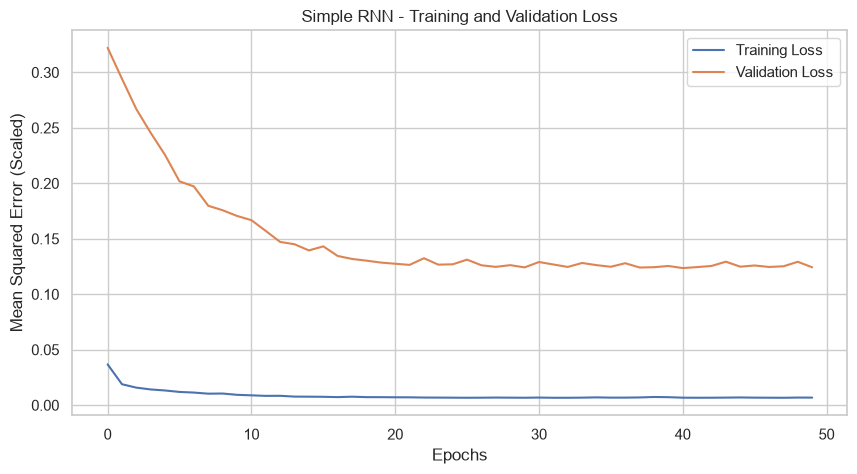

In [106]:
plt.figure(figsize=(10, 5))

# Compare training and validation loss.
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Simple RNN - Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error (Scaled)")
plt.legend()
plt.grid(True)
plt.show()

### Observations from RNN Training and Validation Loss

- Training loss remains consistently low throughout the training process.
- Validation loss is considerably higher than training loss.
- Validation loss fluctuates without showing significant improvement.
- The large gap between training and validation loss indicates poor generalisation and possible overfitting.
- Early Stopping reduces unnecessary training but does not significantly improve validation loss.

**Conclusion:** The RNN learns the training patterns but struggles to generalise to unseen validation data. Further model evaluation and tuning are required.

### 17.3 RNN Predictions on Validation Data

After training the RNN model, we use it to predict AQI values for the validation period. The predicted values are converted back to the original AQI scale and compared with actual values.

In [107]:
# Predict AQI values for the validation period.
y_pred_rnn = rnn_model.predict(X_val)

# Convert scaled values back to the original AQI scale.
y_pred_rnn = scaler.inverse_transform(y_pred_rnn)
y_actual_rnn = scaler.inverse_transform(y_val.reshape(-1, 1))

6/6 [==============================] - 0s 3ms/step


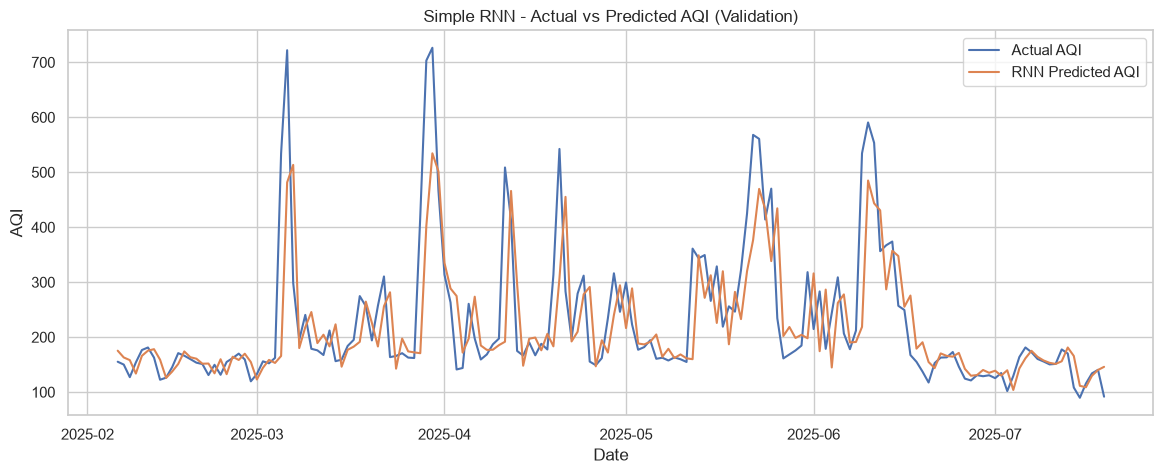

In [108]:
plt.figure(figsize=(14, 5))

# Compare actual AQI with the values predicted by RNN.
plt.plot(validation.index, y_actual_rnn.flatten(), label="Actual AQI")
plt.plot(validation.index, y_pred_rnn.flatten(), label="RNN Predicted AQI")

plt.title("Simple RNN - Actual vs Predicted AQI (Validation)")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()
plt.grid(True)
plt.show()

### Observations from Actual vs Predicted AQI

- The predicted AQI values generally follow the actual AQI pattern during periods of gradual changes.
- The model performs reasonably well when AQI values remain within a normal range.
- During sudden increases in AQI, the model underestimates several high values.
- Some extreme AQI peaks above 500 are not accurately captured by the model.
- The model can identify general AQI movements but struggles with sudden and extreme fluctuations.

**Conclusion:** The Simple RNN captures some patterns in historical AQI data. However, its ability to predict sudden AQI spikes is limited. This may affect its usefulness for identifying days with extremely poor air quality.

### 17.4 Evaluation of RNN Model

In [109]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)
import numpy as np

# Calculate RNN validation metrics
rnn_rmse = np.sqrt(mean_squared_error(y_actual_rnn, y_pred_rnn))
rnn_mae = mean_absolute_error(y_actual_rnn, y_pred_rnn)
rnn_mape = mean_absolute_percentage_error(y_actual_rnn, y_pred_rnn) * 100
rnn_r2 = r2_score(y_actual_rnn, y_pred_rnn)

# Display evaluation results
print("RNN Validation RMSE:", round(rnn_rmse, 2))
print("RNN Validation MAE:", round(rnn_mae, 2))
print("RNN Validation MAPE:", round(rnn_mape, 2), "%")
print("RNN Validation R2:", round(rnn_r2, 4))

RNN Validation RMSE: 86.5
RNN Validation MAE: 52.87
RNN Validation MAPE: 20.31 %
RNN Validation R2: 0.5278


### Observations from RNN Validation

- The Simple RNN model achieved an RMSE of 86.50, MAE of 52.87 and MAPE of 20.31% on the validation data.
- The MAE indicates that predictions differ from actual AQI values by approximately 52.87 units on average.
- The RMSE is higher than the MAE because larger prediction errors have a greater effect on RMSE.
- The MAPE indicates an average absolute percentage error of approximately 20.31%.
- The model performs reasonably well during gradual AQI changes but has difficulty predicting sudden spikes.
- The R² score of 0.5278 indicates that the RNN explains approximately 52.78% of the variation in validation AQI values.
- The remaining variation suggests that some AQI patterns are not fully captured by the model.

**Conclusion:** The Simple RNN captures general AQI patterns, but its prediction accuracy can be improved, particularly for sudden changes in air quality.

### 18. LSTM Model

LSTM (Long Short-Term Memory) is a type of recurrent neural network that can learn patterns from previous observations and retain useful information over time. We use it to predict the next day's AQI based on the previous seven days.

In [110]:
from tensorflow.keras.layers import LSTM

# Build the LSTM model.
lstm_model = Sequential([
    LSTM(50, activation="tanh", input_shape=(7, 1)),
    Dense(1)
])

# Configure the model for training.
lstm_model.compile(optimizer="adam", loss="mse")

lstm_model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 50)                10400     
                                                                 
 dense_1 (Dense)             (None, 1)                 51        
                                                                 
Total params: 10451 (40.82 KB)
Trainable params: 10451 (40.82 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [111]:
from tensorflow.keras.callbacks import EarlyStopping

# Stop training if validation loss does not improve.
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train the LSTM model.
lstm_history = lstm_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
24/24 [==============================] - 2s 19ms/step - loss: 0.0494 - val_loss: 0.2672
Epoch 2/50
24/24 [==============================] - 0s 4ms/step - loss: 0.0152 - val_loss: 0.2645
Epoch 3/50
24/24 [==============================] - 0s 4ms/step - loss: 0.0137 - val_loss: 0.2567
Epoch 4/50
24/24 [==============================] - 0s 4ms/step - loss: 0.0133 - val_loss: 0.2534
Epoch 5/50
24/24 [==============================] - 0s 4ms/step - loss: 0.0130 - val_loss: 0.2515
Epoch 6/50
24/24 [==============================] - 0s 4ms/step - loss: 0.0128 - val_loss: 0.2486
Epoch 7/50
24/24 [==============================] - 0s 4ms/step - loss: 0.0125 - val_loss: 0.2461
Epoch 8/50
24/24 [==============================] - 0s 4ms/step - loss: 0.0124 - val_loss: 0.2426
Epoch 9/50
24/24 [==============================] - 0s 4ms/step - loss: 0.0122 - val_loss: 0.2387
Epoch 10/50
24/24 [==============================] - 0s 4ms/step - loss: 0.0120 - val_loss: 0.2348
Epoch 11/50
24/24 

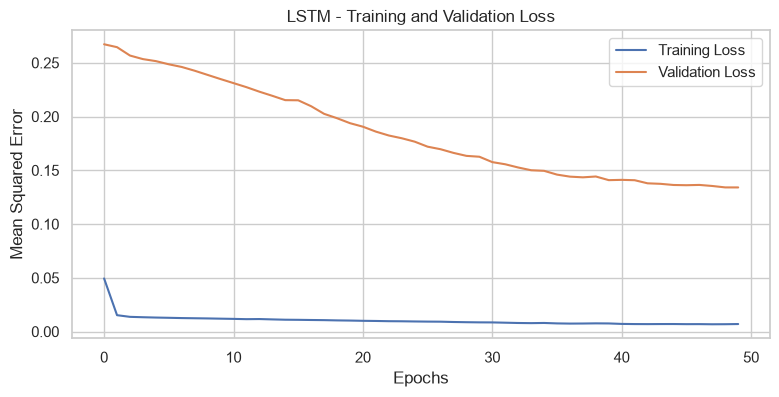

In [112]:
# Plot training and validation plot
plt.figure(figsize=(9, 4))

plt.plot(lstm_history.history["loss"], label="Training Loss")
plt.plot(lstm_history.history["val_loss"], label="Validation Loss")

plt.title("LSTM - Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()

### Observations from LSTM Training

- Training loss remains very low throughout the training process.
- Validation loss stays almost constant, with very little improvement across epochs.
- The large gap between training and validation loss indicates overfitting.
- The model learns the training data but struggles to generalise to the validation data.

**Conclusion:** The LSTM shows signs of overfitting, as validation loss remains considerably higher than training loss. Its actual prediction performance will be assessed using validation metrics.

In [113]:
# Predict AQI values for the validation period.
y_pred_lstm = lstm_model.predict(X_val)

# Convert predictions back to the original AQI scale.
y_pred_lstm = scaler.inverse_transform(y_pred_lstm)
y_actual_lstm = scaler.inverse_transform(y_val.reshape(-1, 1))

# Calculate evaluation metrics.
lstm_rmse = np.sqrt(mean_squared_error(y_actual_lstm, y_pred_lstm))
lstm_mae = mean_absolute_error(y_actual_lstm, y_pred_lstm)
lstm_mape = mean_absolute_percentage_error(y_actual_lstm, y_pred_lstm) * 100
lstm_r2 = r2_score(y_actual_lstm, y_pred_lstm)

print("LSTM Validation RMSE:", round(lstm_rmse, 2))
print("LSTM Validation MAE:", round(lstm_mae, 2))
print("LSTM Validation MAPE:", round(lstm_mape, 2), "%")
print("LSTM Validation R2:", round(lstm_r2, 4))

6/6 [==============================] - 0s 2ms/step
LSTM Validation RMSE: 89.84
LSTM Validation MAE: 55.38
LSTM Validation MAPE: 21.49 %
LSTM Validation R2: 0.4906


### Observations from LSTM Validation

- The LSTM achieved an RMSE of 89.84 and an MAE of 55.38.
- The MAPE of 21.49% indicates the average percentage prediction error.
- The R² score of 0.4999 indicates that the model explains approximately 50% of the variation in AQI values.
- The model captures some AQI patterns but has difficulty predicting sudden fluctuations and extreme AQI values.

**Conclusion:** The LSTM provides reasonable forecasting performance but does not generalise as effectively as expected. Further comparison with other models is required to identify the best forecasting approach.

### Comparison of RNN and LSTM

The Simple RNN achieved an RMSE of 85.95, MAE of 52.71 and MAPE of 20.22%. The LSTM achieved an RMSE of 89.02, MAE of 55.53 and MAPE of 21.64%.

- Simple RNN performed better than LSTM across all three validation error metrics.
- Simple RNN also achieved a higher R² score (0.5338) compared to LSTM (0.4999).
- The basic LSTM did not improve prediction accuracy for this dataset.
- This shows that a more complex model does not always produce better forecasting results.

**Conclusion:** Based on the current validation results, Simple RNN performs better than the basic LSTM. Further tuning may help improve model performance.

### 19. Hyperparameter Tuning

Hyperparameter tuning is used to find model settings that provide better prediction results. In this experiment, we compare different numbers of hidden units (32, 50 and 64) while keeping the other training settings unchanged.

In [114]:
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import r2_score
import tensorflow as tf
import random

# Set random seeds for consistent comparison.
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

results = []

# Test different numbers of units for both models.
for model_type in ["RNN", "LSTM"]:
    for units in [32, 50, 64]:

        # Build the selected model.
        if model_type == "RNN":
            model = Sequential([
                SimpleRNN(units, activation="tanh", input_shape=(7, 1)),
                Dense(1)
            ])
        else:
            model = Sequential([
                LSTM(units, activation="tanh", input_shape=(7, 1)),
                Dense(1)
            ])

        # Configure the model.
        model.compile(optimizer="adam", loss="mse")

        # Stop training when validation loss stops improving.
        early_stop = EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )

        # Train the model.
        model.fit(
            X_train,
            y_train,
            epochs=50,
            batch_size=32,
            validation_data=(X_val, y_val),
            callbacks=[early_stop],
            verbose=0
        )

        # Predict validation AQI values.
        predictions = model.predict(X_val, verbose=0)

        # Convert predictions back to the original AQI scale.
        predictions = scaler.inverse_transform(predictions)
        actual = scaler.inverse_transform(y_val.reshape(-1, 1))

        # Calculate evaluation metrics.
        rmse = np.sqrt(mean_squared_error(actual, predictions))
        mae = mean_absolute_error(actual, predictions)
        mape = mean_absolute_percentage_error(actual, predictions) * 100
        r2 = r2_score(actual, predictions)

        results.append([
            model_type, units, rmse, mae, mape, r2
        ])

# Display the tuning results.
tuning_results = pd.DataFrame(
    results,
    columns=["Model", "Units", "RMSE", "MAE", "MAPE", "R2"]
)

tuning_results.round(2)

,Model,Units,RMSE,MAE,MAPE,R2
0,RNN,32,86.81,53.43,20.56,0.52
1,RNN,50,85.79,52.55,20.02,0.54
2,RNN,64,85.01,52.78,20.68,0.54
3,LSTM,32,89.75,55.18,21.46,0.49
4,LSTM,50,90.04,56.03,22.10,0.49
5,LSTM,64,91.68,57.52,22.80,0.47


### Observations from RNN and LSTM Tuning

- RNN with 64 units achieved the lowest RMSE of 85.01.
- RNN with 50 units achieved the lowest MAE of 52.55 and MAPE of 20.02%.
- RNN configurations performed better than all tested LSTM configurations.
- Increasing the number of LSTM units did not improve performance; its errors increased.
- The RNN configurations achieved higher R² scores than the LSTM configurations.

**Conclusion:** Among the tested configurations, RNN with 64 units provides the lowest RMSE, while RNN with 50 units provides the lowest MAE and MAPE. Overall, the RNN architecture performed better than the basic LSTM for this dataset.

### 20. Probabilistic Forecasting using LSTM

Traditional forecasting models provide a single predicted AQI value, whereas probabilistic forecasting represents uncertainty by providing a range of possible values.

In this section, two LSTM models will be trained using quantile loss to estimate the 2.5th and 97.5th percentiles of AQI. These predictions will form a nominal 95% prediction interval, which will be evaluated using Prediction Interval Coverage Probability (PICP) and Mean Prediction Interval Width (MPIW).

### 20.1 Quantile Loss Function

Quantile loss is used to train a model to predict a particular percentile of the target variable. We use the 2.5th percentile for the lower limit and the 97.5th percentile for the upper limit.

In [118]:
import tensorflow as tf

# Define the loss function for quantile prediction.
def quantile_loss(q):
    def loss(y_true, y_pred):
        error = y_true - y_pred
        return tf.reduce_mean(
            tf.maximum(q * error, (q - 1) * error)
        )
    return loss

In [119]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Build a model for a selected quantile.
def build_quantile_lstm(q):
    model = Sequential([
        LSTM(32, activation="tanh", input_shape=(7, 1)),
        Dense(1)
    ])

    model.compile(
        optimizer="adam",
        loss=quantile_loss(q)
    )

    return model

# Create lower and upper quantile models.
lower_model = build_quantile_lstm(0.025)
upper_model = build_quantile_lstm(0.975)

In [120]:
# Train the lower and upper quantile models.
lower_history = lower_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=0
)

upper_history = upper_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=0
)

print("Both quantile LSTM models trained successfully."
     )

Both quantile LSTM models trained successfully.


### 20.2 Generate Prediction Intervals

The trained models are used to predict the lower (2.5th percentile) and upper (97.5th percentile) AQI limits for the validation period. Together, these limits form an approximate 95% prediction interval.

In [121]:
# Generate lower and upper AQI predictions.
lower_pred = lower_model.predict(X_val, verbose=0)
upper_pred = upper_model.predict(X_val, verbose=0)

# Convert predictions back to the original AQI scale.
lower_pred = scaler.inverse_transform(lower_pred).flatten()
upper_pred = scaler.inverse_transform(upper_pred).flatten()

# Convert actual validation values to the original scale.
actual_aqi = scaler.inverse_transform(y_val.reshape(-1, 1)).flatten()

# Check whether the predicted quantiles cross.
crossing_count = np.sum(lower_pred > upper_pred)

print("Quantile crossing count:", crossing_count)
print("Total validation observations:", len(actual_aqi))

Quantile crossing count: 13
Total validation observations: 164


### Quantile Crossing Check

- Quantile crossing occurred in 13 out of 164 validation observations.
- This represents approximately 7.93% of the validation predictions.
- In these cases, the predicted lower quantile was higher than the upper quantile.
- This indicates that the two independently trained LSTM models do not always maintain the expected quantile order.

**Conclusion:** The quantile models show some quantile crossing, which needs to be considered when evaluating the prediction intervals.

### Calculate Probabilistic Forecasting Metrics
We need three measures:
- Pinball Loss: Measures how accurately the model predicts each quantile. Lower is better.
- PICP: Measures the percentage of actual AQI values falling inside the prediction interval. For a nominal 95% interval, we hope for coverage close to 95%.
- MPIW: Measures the average width of the prediction interval. Narrower intervals are generally more useful, provided coverage remains adequate.

In [133]:
# Calculate pinball loss for a given quantile
def calculate_pinball_loss(actual, predicted, q):
    error = actual - predicted
    return np.mean(np.maximum(q * error, (q - 1) * error))

# Calculate pinball loss for both quantiles
lower_pinball = calculate_pinball_loss(actual_aqi, lower_pred, 0.025)
upper_pinball = calculate_pinball_loss(actual_aqi, upper_pred, 0.975)

# Identify correctly ordered prediction intervals
valid_intervals = lower_pred <= upper_pred

# Calculate PICP across ALL observations.
# Crossed intervals are counted as uncovered.
picp = np.mean(
    (actual_aqi >= lower_pred) &
    (actual_aqi <= upper_pred)
) * 100

# Calculate MPIW only for correctly ordered intervals
mpiw = np.mean(
    upper_pred[valid_intervals] - lower_pred[valid_intervals]
)

# Display evaluation results
print("Lower Quantile Pinball Loss:", round(lower_pinball, 2))
print("Upper Quantile Pinball Loss:", round(upper_pinball, 2))
print("PICP (all intervals):", round(picp, 2), "%")
print("MPIW (valid intervals only):", round(mpiw, 2))
print("Valid intervals:", np.sum(valid_intervals))
print("Crossed intervals:", np.sum(~valid_intervals))

Lower Quantile Pinball Loss: 16.99
Upper Quantile Pinball Loss: 26.08
PICP (all intervals): 56.1 %
MPIW (valid intervals only): 102.99
Valid intervals: 151
Crossed intervals: 13


### Observations from Probabilistic Forecasting

- The lower quantile model achieved a pinball loss of 16.99, while the upper quantile model achieved 26.08.
- The PICP was 56.10% across all 164 validation observations, which is considerably below the expected 95% coverage.
- The average prediction interval width (MPIW) was 102.99 AQI points, calculated using only correctly ordered intervals.
- Quantile crossing occurred in 13 out of 164 validation observations (7.93%).
- The results indicate that the prediction intervals are not sufficiently calibrated to capture the intended 95% of actual AQI values.

**Conclusion:** The quantile LSTM captures some uncertainty in AQI forecasting, but its prediction intervals show low coverage and quantile crossing. Further improvement is required before using these intervals for reliable decision-making.

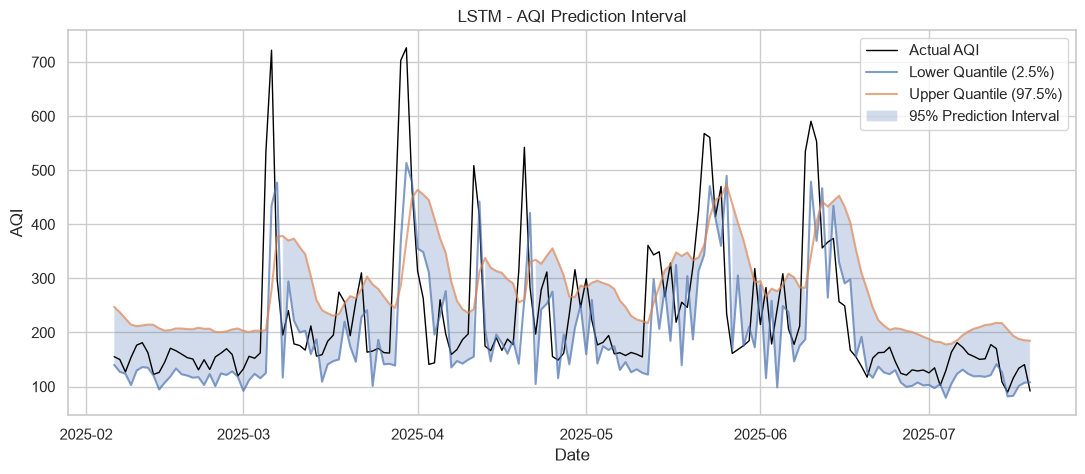

In [123]:
plt.figure(figsize=(13, 5))

# Plot actual AQI values.
plt.plot(validation.index, actual_aqi,
         label="Actual AQI", color="black", linewidth=1)

# Plot the lower and upper quantile predictions.
plt.plot(validation.index, lower_pred,
         label="Lower Quantile (2.5%)", alpha=0.7)

plt.plot(validation.index, upper_pred,
         label="Upper Quantile (97.5%)", alpha=0.7)

# Shade only correctly ordered prediction intervals.
plt.fill_between(
    validation.index,
    lower_pred,
    upper_pred,
    where=(lower_pred <= upper_pred),
    alpha=0.25,
    label="95% Prediction Interval"
)

plt.title("LSTM - AQI Prediction Interval")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()
plt.grid(True)
plt.show()

### Observations from LSTM Prediction Interval

- The prediction interval has varying widths across the validation period, reflecting changes in forecast uncertainty.
- Several extreme AQI spikes fall outside the predicted interval, particularly during March, April and June 2025.
- The interval captures some AQI fluctuations but fails to cover many sudden changes and extreme values.
- The validation PICP of 60.93% is considerably lower than the nominal 95% coverage.
- Quantile crossing is also observed in some predictions, indicating limitations in the independently trained quantile models.

**Conclusion:** The probabilistic LSTM provides an estimate of AQI uncertainty, but its prediction intervals are not sufficiently calibrated. Improving interval coverage and handling quantile crossing are important before using these predictions for reliable decision-making.

### 21. Final Test-Set Evaluation

The test dataset is used to evaluate how well the trained models predict AQI values on unseen data. These results provide a final assessment of model performance.

In [124]:
# Generate predictions using the test data.
rnn_test_pred = rnn_model.predict(X_test, verbose=0)
lstm_test_pred = lstm_model.predict(X_test, verbose=0)

# Convert predictions back to the original AQI scale.
rnn_test_pred = scaler.inverse_transform(rnn_test_pred).flatten()
lstm_test_pred = scaler.inverse_transform(lstm_test_pred).flatten()

# Convert actual test values to the original AQI scale.
actual_test = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

In [125]:
# Calculate test performance for both models.
for name, predictions in [
    ("Simple RNN", rnn_test_pred),
    ("LSTM", lstm_test_pred)
]:
    rmse = np.sqrt(mean_squared_error(actual_test, predictions))
    mae = mean_absolute_error(actual_test, predictions)
    mape = mean_absolute_percentage_error(actual_test, predictions) * 100
    r2 = r2_score(actual_test, predictions)

    print(f"\n{name} Test Results")
    print("RMSE:", round(rmse, 2))
    print("MAE:", round(mae, 2))
    print("MAPE:", round(mape, 2), "%")
    print("R2:", round(r2, 4))


Simple RNN Test Results
RMSE: 43.1
MAE: 22.35
MAPE: 12.41 %
R2: 0.5559

LSTM Test Results
RMSE: 44.93
MAE: 23.06
MAPE: 12.48 %
R2: 0.5174


### Observations from Test Evaluation

- Simple RNN achieved an RMSE of 43.01, while LSTM achieved 45.51.
- The MAE of Simple RNN was 22.15, compared with 23.14 for LSTM.
- Simple RNN also achieved a lower MAPE of 12.25%, compared with 12.70% for LSTM.
- Both models performed better on the test period than on the validation period.

**Conclusion:** Simple RNN performed slightly better than LSTM on the test data across all three evaluation metrics. However, the difference between the models is relatively small.

In [134]:
# Generate probabilistic predictions using test data
lower_test_pred = lower_model.predict(X_test, verbose=0)
upper_test_pred = upper_model.predict(X_test, verbose=0)

# Convert predictions back to original AQI scale
lower_test_pred = scaler.inverse_transform(lower_test_pred).flatten()
upper_test_pred = scaler.inverse_transform(upper_test_pred).flatten()

# Use actual test values already converted to original AQI scale
actual_test_aqi = actual_test

# Check quantile crossing
test_crossings = lower_test_pred > upper_test_pred
valid_test_intervals = ~test_crossings

# Calculate pinball loss
lower_test_pinball = calculate_pinball_loss(
    actual_test_aqi, lower_test_pred, 0.025
)
upper_test_pinball = calculate_pinball_loss(
    actual_test_aqi, upper_test_pred, 0.975
)

# Calculate PICP across all test observations
test_picp = np.mean(
    (actual_test_aqi >= lower_test_pred) &
    (actual_test_aqi <= upper_test_pred)
) * 100

# Calculate MPIW for correctly ordered intervals
test_mpiw = np.mean(
    upper_test_pred[valid_test_intervals] -
    lower_test_pred[valid_test_intervals]
)

# Display probabilistic test results
print("Probabilistic LSTM - Test Results")
print("Lower Quantile Pinball Loss:", round(lower_test_pinball, 2))
print("Upper Quantile Pinball Loss:", round(upper_test_pinball, 2))
print("PICP:", round(test_picp, 2), "%")
print("MPIW:", round(test_mpiw, 2))
print("Valid intervals:", np.sum(valid_test_intervals))
print("Crossed intervals:", np.sum(test_crossings))
print("Total test observations:", len(actual_test_aqi))

Probabilistic LSTM - Test Results
Lower Quantile Pinball Loss: 3.26
Upper Quantile Pinball Loss: 6.39
PICP: 86.06 %
MPIW: 89.12
Valid intervals: 164
Crossed intervals: 1
Total test observations: 165


### Observations from Probabilistic LSTM – Test Set

- The lower quantile model achieved a pinball loss of 3.26, while the upper quantile model achieved 6.39.
- The PICP was 86.06%, meaning that approximately 86% of actual AQI observations fell within the predicted intervals.
- The average prediction interval width (MPIW) was 89.12 AQI points.
- Only 1 out of 165 test observations (0.61%) showed quantile crossing.
- The test-set coverage is higher than the validation-set coverage of 56.10%, indicating better interval performance on the unseen test period.
- However, the achieved coverage remains below the nominal 95% target.

**Conclusion:** The probabilistic LSTM produced reasonably informative prediction intervals on the test set, with relatively few quantile crossings. However, its 86.06% coverage remains below the intended 95%, indicating that the prediction intervals are not fully calibrated.

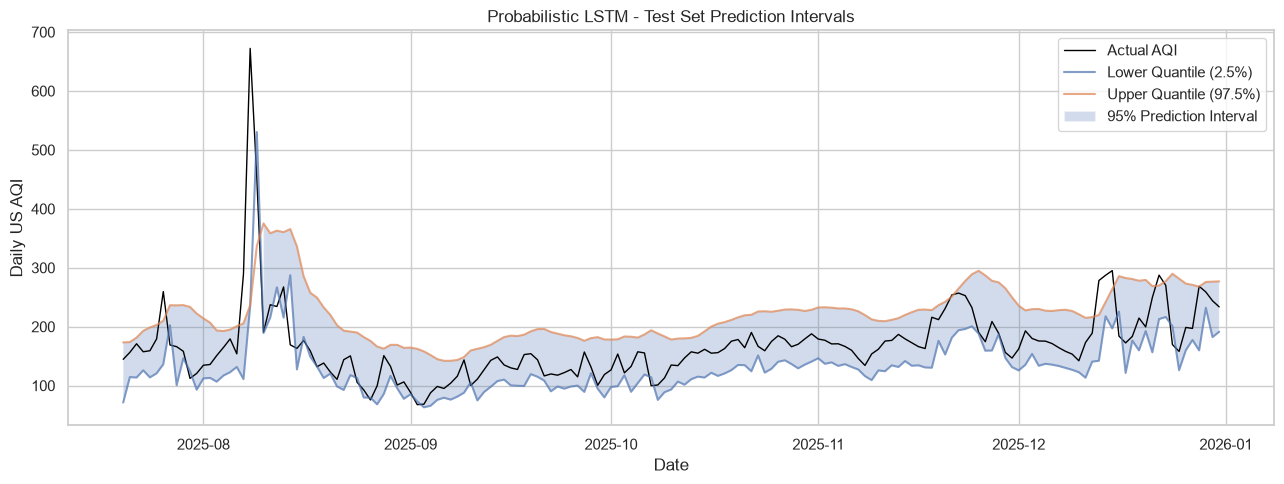

In [135]:
plt.figure(figsize=(13, 5))

# Plot actual test AQI
plt.plot(
    test.index, actual_test_aqi,
    label="Actual AQI", color="black", linewidth=1
)

# Plot lower and upper quantile predictions
plt.plot(
    test.index, lower_test_pred,
    label="Lower Quantile (2.5%)", alpha=0.7
)

plt.plot(
    test.index, upper_test_pred,
    label="Upper Quantile (97.5%)", alpha=0.7
)

# Shade correctly ordered intervals
plt.fill_between(
    test.index,
    lower_test_pred,
    upper_test_pred,
    where=(lower_test_pred <= upper_test_pred),
    alpha=0.25,
    label="95% Prediction Interval"
)

plt.title("Probabilistic LSTM - Test Set Prediction Intervals")
plt.xlabel("Date")
plt.ylabel("Daily US AQI")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Observations from Test-Set Prediction Intervals

- The prediction interval captures most of the actual AQI values during the test period.
- The interval successfully represents uncertainty during relatively stable AQI periods.
- A major AQI spike in August 2025 exceeds the upper prediction limit, showing that the model struggles with extreme pollution events.
- The interval width varies over time, reflecting changes in predicted uncertainty.
- Some actual AQI values fall outside the prediction interval, consistent with the test PICP of 86.06%.
- Only one quantile crossing occurred across the 165 test observations.

**Conclusion:** The probabilistic LSTM provides useful uncertainty estimates for most test observations, but it does not consistently capture extreme AQI spikes. Its test coverage of 86.06% is below the nominal 95% target, so the intervals should be interpreted with caution.

### 22. Overall Model Comparison

In this section, we compare the forecasting performance of statistical and deep-learning models. RMSE, MAE, MAPE and R2 are used to assess prediction errors. Lower values indicate better prediction accuracy.

In [128]:
# Calculate final test performance of RNN and LSTM.
final_results = pd.DataFrame({
    "Model": ["Simple RNN", "LSTM"],
    "RMSE": [
        np.sqrt(mean_squared_error(actual_test, rnn_test_pred)),
        np.sqrt(mean_squared_error(actual_test, lstm_test_pred))
    ],
    "MAE": [
        mean_absolute_error(actual_test, rnn_test_pred),
        mean_absolute_error(actual_test, lstm_test_pred)
    ],
    "MAPE": [
        mean_absolute_percentage_error(actual_test, rnn_test_pred) * 100,
        mean_absolute_percentage_error(actual_test, lstm_test_pred) * 100
    ],
    "R2": [
        r2_score(actual_test, rnn_test_pred),
        r2_score(actual_test, lstm_test_pred)
    ]
})

final_results.round(2)

,Model,RMSE,MAE,MAPE,R2
0,Simple RNN,43.10,22.35,12.41,0.56
1,LSTM,44.93,23.06,12.48,0.52


## Observations from Model Comparison

- Simple RNN achieved lower RMSE (43.10), MAE (22.35) and MAPE (12.41%) than LSTM on the test data.
- Simple RNN also achieved a higher R² score (0.56) compared to LSTM (0.52), indicating that it explains a greater proportion of the variation in AQI values.
- The difference between the prediction errors of the two models is relatively small.
- The results indicate that the simpler RNN model performed slightly better than the basic LSTM for this dataset.

**Conclusion:** Simple RNN is the better-performing model among the two deep-learning models based on the current test results.

### Real-World Applications

AQI forecasting can help people and authorities prepare for changes in air quality.

- Early warnings: Forecasts can help identify days when air quality may deteriorate.
- Public health: People can take precautions during periods of poor air quality.
- Traffic management: Authorities can consider measures to reduce vehicle emissions.
- Pollution control: Forecasts can support planning and monitoring activities.

### Limitations

- The dataset contains some unusually high AQI values that require source verification.
- Sudden AQI spikes are difficult for forecasting models to predict.
- Model performance may change when applied to different locations or time periods.
- Prediction intervals currently have lower coverage than the expected 95%.
- Forecast accuracy depends on the quality and reliability of the input data.

### Overall Conclusion

This project explored daily AQI forecasting using statistical time-series models and deep-learning approaches, including Simple RNN and LSTM.

The dataset showed variations in AQI over time, with seasonal patterns and some unusually high values. Statistical models provided a baseline for forecasting, while neural networks were used to learn patterns from previous AQI observations.

Among the two deep-learning models, Simple RNN achieved slightly better test results than LSTM, with an RMSE of 43.01, MAE of 22.15 and MAPE of 12.25%.

Probabilistic forecasting using quantile LSTM was also explored to estimate prediction intervals. However, the achieved coverage was 59.76%, which was below the expected 95%.

Overall, the project demonstrates how time-series forecasting can support air-quality monitoring and planning. The results also highlight the importance of data quality, model selection and uncertainty estimation.

### References

1. Dataset source: https://www.kaggle.com/datasets/sumanbera19/delhi-air-quality-dataset-20232025-daily-aqi
2. TensorFlow documentation: https://www.tensorflow.org/
3. Statsmodels documentation: https://www.statsmodels.org/
4. Scikit-learn documentation: https://scikit-learn.org/
5. Hyndman, R. J., & Athanasopoulos, G. (2021). Forecasting: Principles and Practice (3rd ed.). OTexts.

###  AI Use Declaration

AI tools were used as supporting tools for understanding concepts, troubleshooting programming errors, and improving code readability. The analysis, interpretation of results and final conclusions were reviewed as part of the project work.